# 01 · Explore PBMCs: raw counts to cell-type hypotheses

**Stage 2 — one sample, one donor.** Work through each cell in order, inspect the plots,
and use **Kernel → Restart Kernel and Run All Cells** to verify the entire analysis.
Select **RNA-seq Stage 2 (Python 3.11)**; installation and launch instructions are in
`docs/stage-2.md`. Run from the repository or its `notebooks/` folder.

Inputs are the full-depth Stage 1 count matrix and its matching Ensembl 108 mapping.
Outputs include `results/annotated.h5ad`, marker tables, QC decisions, and figures.
The small read subset is for execution tests; this notebook uses the full sample.

We keep three representations separate: **raw UMI counts** for QC, **log1p(CP10k)**
expression for markers/annotation, and **scaled HVGs** solely for PCA. We inspect
CellTypist labels against markers rather than treating model predictions as ground truth.
This notebook does not perform formal empty-droplet testing, ambient-RNA correction,
or dedicated doublet detection. Its QC thresholds are explicit exploratory decisions.

## Setup: reproducible parameters and an isolated kernel

All analysis settings live in `nextflow.config`. Nextflow only parses configuration
here; it does not run the analysis. The random seed fixes stochastic steps within
this pinned environment. Numerical results may still vary across hardware or versions.
Project-local caches keep this notebook from writing model files into your home directory.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, hashlib, platform
import importlib.metadata as metadata

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'nextflow.config').is_file() and (p / 'samplesheet.csv').is_file()), None)
assert ROOT is not None, 'Launch Jupyter from the rna-seq repository.'
os.environ['MPLCONFIGDIR'] = str(ROOT / 'work/cache/matplotlib')
os.environ['NUMBA_CACHE_DIR'] = str(ROOT / 'work/cache/numba')
os.environ['CELLTYPIST_FOLDER'] = str(ROOT / 'work/cache/celltypist')
os.environ['NXF_HOME'] = str(ROOT / 'work/nextflow')
os.environ['NXF_VER'] = '26.10.5'
os.environ['JAVA_HOME'] = str(Path(sys.executable).parent.parent / 'lib/jvm')
config_result = subprocess.run(
    ['nextflow', '-C', str(ROOT / 'nextflow.config'), 'config', '-o', 'json'],
    cwd=ROOT, capture_output=True, text=True, check=True)
P = json.loads(config_result.stdout)['params']
OUT = ROOT / P['analysis_dir']
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
from IPython.display import display, Markdown

np.random.seed(P['seed'])
sc.settings.verbosity = 2
sc.settings.n_jobs = P['threads']
sc.set_figure_params(dpi=100, dpi_save=160, facecolor='white', fontsize=10)
plt.rcParams['figure.constrained_layout.use'] = False  # Scanpy manages its own grids.
versions = {name: metadata.version(name) for name in
            ['scanpy', 'anndata', 'celltypist', 'igraph', 'leidenalg', 'numpy',
             'scipy', 'pandas', 'scikit-learn', 'ipykernel', 'ipywidgets', 'notebook', 'nbclient']}
display(pd.Series(versions, name='installed version').to_frame())
display(pd.Series({k: v for k, v in P.items() if k.startswith(
    ('qc_', 'hvg_', 'pca_', 'neighbors_', 'leiden_', 'umap_', 'normalization_'))},
    name='configuration').to_frame())

,installed version
scanpy,1.11.5
anndata,0.11.4
celltypist,1.7.1
igraph,0.11.9
leidenalg,0.10.2
numpy,2.4.6
scipy,1.17.1
pandas,2.2.3
scikit-learn,1.9.1
ipykernel,6.29.5


,configuration
qc_min_genes,200
qc_max_genes,5000
qc_min_counts,1000
qc_max_counts,30000
qc_max_pct_mt,20
qc_gene_min_cells,3
normalization_target,10000
hvg_n_top_genes,2000
hvg_flavor,seurat
pca_components,50


## 1 · Load counts and map identifiers without losing molecules

AnnData uses rows for barcodes and columns for genes. The input is **unfiltered**:
most rows are empty droplets or low-count barcodes, not confirmed cells.

The local `t2g.txt` is the exact reference used by kallisto. We read its first three
columns explicitly because it has additional annotation columns. We use exact
versioned Ensembl IDs, with an unambiguous version-stripped fallback if needed.
Missing symbols retain their Ensembl ID; they are not discarded. Repeated symbols
are combined by **summing raw counts before normalization**. The original IDs and
the full mapping table remain available for audit; symbol aggregation can combine
distinct loci, so it is an explicit annotation convention rather than a claim
that those loci are biologically identical. No online mapping database is needed.

In [2]:
source = sc.read_h5ad(ROOT / P['analysis_input'])
assert sp.issparse(source.X) and source.obs_names.is_unique
assert np.isfinite(source.X.data).all() and (source.X.data >= 0).all()
assert np.equal(source.X.data, np.floor(source.X.data)).all()
input_shape = source.shape
input_total_umis = float(source.X.sum())
reference = pd.read_csv(ROOT / P['t2g'], sep='\t', header=None, usecols=[0, 1, 2],
                        names=['transcript_id', 'gene_id', 'symbol'], dtype=str,
                        keep_default_na=False)
assert reference.groupby('gene_id')['symbol'].nunique().max() == 1
exact = reference.drop_duplicates('gene_id').set_index('gene_id')['symbol']
base = reference.assign(base_id=reference.gene_id.str.replace(r'\.\d+$', '', regex=True))
unambiguous = base.groupby('base_id')['symbol'].nunique().eq(1)
fallback = base[base.base_id.isin(unambiguous[unambiguous].index)].drop_duplicates(
    'base_id').set_index('base_id')['symbol']
original_ids = pd.Index(source.var_names.astype(str))
ensembl = original_ids.str.startswith('ENSG')
symbols = pd.Series(original_ids, index=original_ids, dtype=object)
symbols.loc[ensembl] = exact.reindex(original_ids[ensembl]).values
missing = ensembl & symbols.isna().to_numpy()
symbols.loc[missing] = fallback.reindex(
    original_ids[missing].str.replace(r'\.\d+$', '', regex=True)).values
symbols = symbols.fillna('').str.strip()
feature_names = pd.Index(np.where(symbols.eq(''), original_ids, symbols))
mapping = pd.DataFrame({'original_id': original_ids, 'gene_symbol': symbols.values,
                        'feature_name': feature_names})
mapping.to_csv(OUT / 'gene_id_mapping.tsv', sep='\t', index=False)
codes, unique_names = pd.factorize(feature_names, sort=False)
projection = sp.csr_matrix((np.ones(len(codes)), (np.arange(len(codes)), codes)),
                           shape=(source.n_vars, len(unique_names)))
grouped = mapping.groupby('feature_name', sort=False)
var = pd.DataFrame(index=pd.Index(unique_names, name='gene'))
var['original_gene_ids'] = grouped.original_id.agg(';'.join).reindex(var.index).values
var['gene_symbol'] = grouped.gene_symbol.first().reindex(var.index).values
var['n_original_ids'] = grouped.size().reindex(var.index).values
adata = ad.AnnData((source.X @ projection).tocsr().astype(np.float32),
                   obs=source.obs.copy(), var=var)
assert np.array_equal(np.asarray(source.X.sum(axis=1)).ravel(),
                      np.asarray(adata.X.sum(axis=1)).ravel())
assert adata.var_names.is_unique
mapping_summary = {'input_barcodes': input_shape[0], 'original_gene_ids': input_shape[1],
                   'merged_features': adata.n_vars, 'ids_without_symbols': int(symbols.eq('').sum()),
                   'symbol_groups_combining_ids': int((var.n_original_ids > 1).sum())}
display(pd.Series(mapping_summary).to_frame('value'))
display(mapping.head())
del source, projection

,value
input_barcodes,237012
original_gene_ids,39546
merged_features,39509
ids_without_symbols,13841
symbol_groups_combining_ids,36


,original_id,gene_symbol,feature_name
0,ENSG00000160072.20,ATAD3B,ATAD3B
1,ENSG00000228037.1,,ENSG00000228037.1
2,ENSG00000142611.17,PRDM16,PRDM16
3,ENSG00000284616.1,,ENSG00000284616.1
4,ENSG00000157911.11,PEX10,PEX10


## 2 · Measure QC before filtering

Detected genes measure library complexity; total counts measure captured UMIs.
Mitochondrial percentage here means **percent of UMI counts assigned to mitochondrial
genes**, not percent of original FASTQ reads. The reference contains only a subset
of mitochondrial gene biotypes, so these percentages are reference-dependent.
High mitochondrial fractions can accompany damaged cells but are not a diagnosis.

We first plot all barcodes on logarithmic axes, then zoom into barcodes with at
least the configured minimum gene count. That zoom is for inspection only; it is
not yet the final filtering step. The rank curve helps separate the high-count
cell-like population from the long low-count tail.

,n_genes_by_counts,total_counts,pct_counts_mt
0.01,283.27,670.03,3.661951
0.05,726.85,1733.35,6.038336
0.25,1652.50,5351.00,8.414670
0.50,2031.00,7211.00,10.012429
0.75,2627.75,9778.75,12.004642
0.95,3920.35,17194.85,20.923316
0.99,4463.73,23739.49,51.801106


237,012 barcodes; 1,204 preliminary candidates; 13 mitochondrial features.


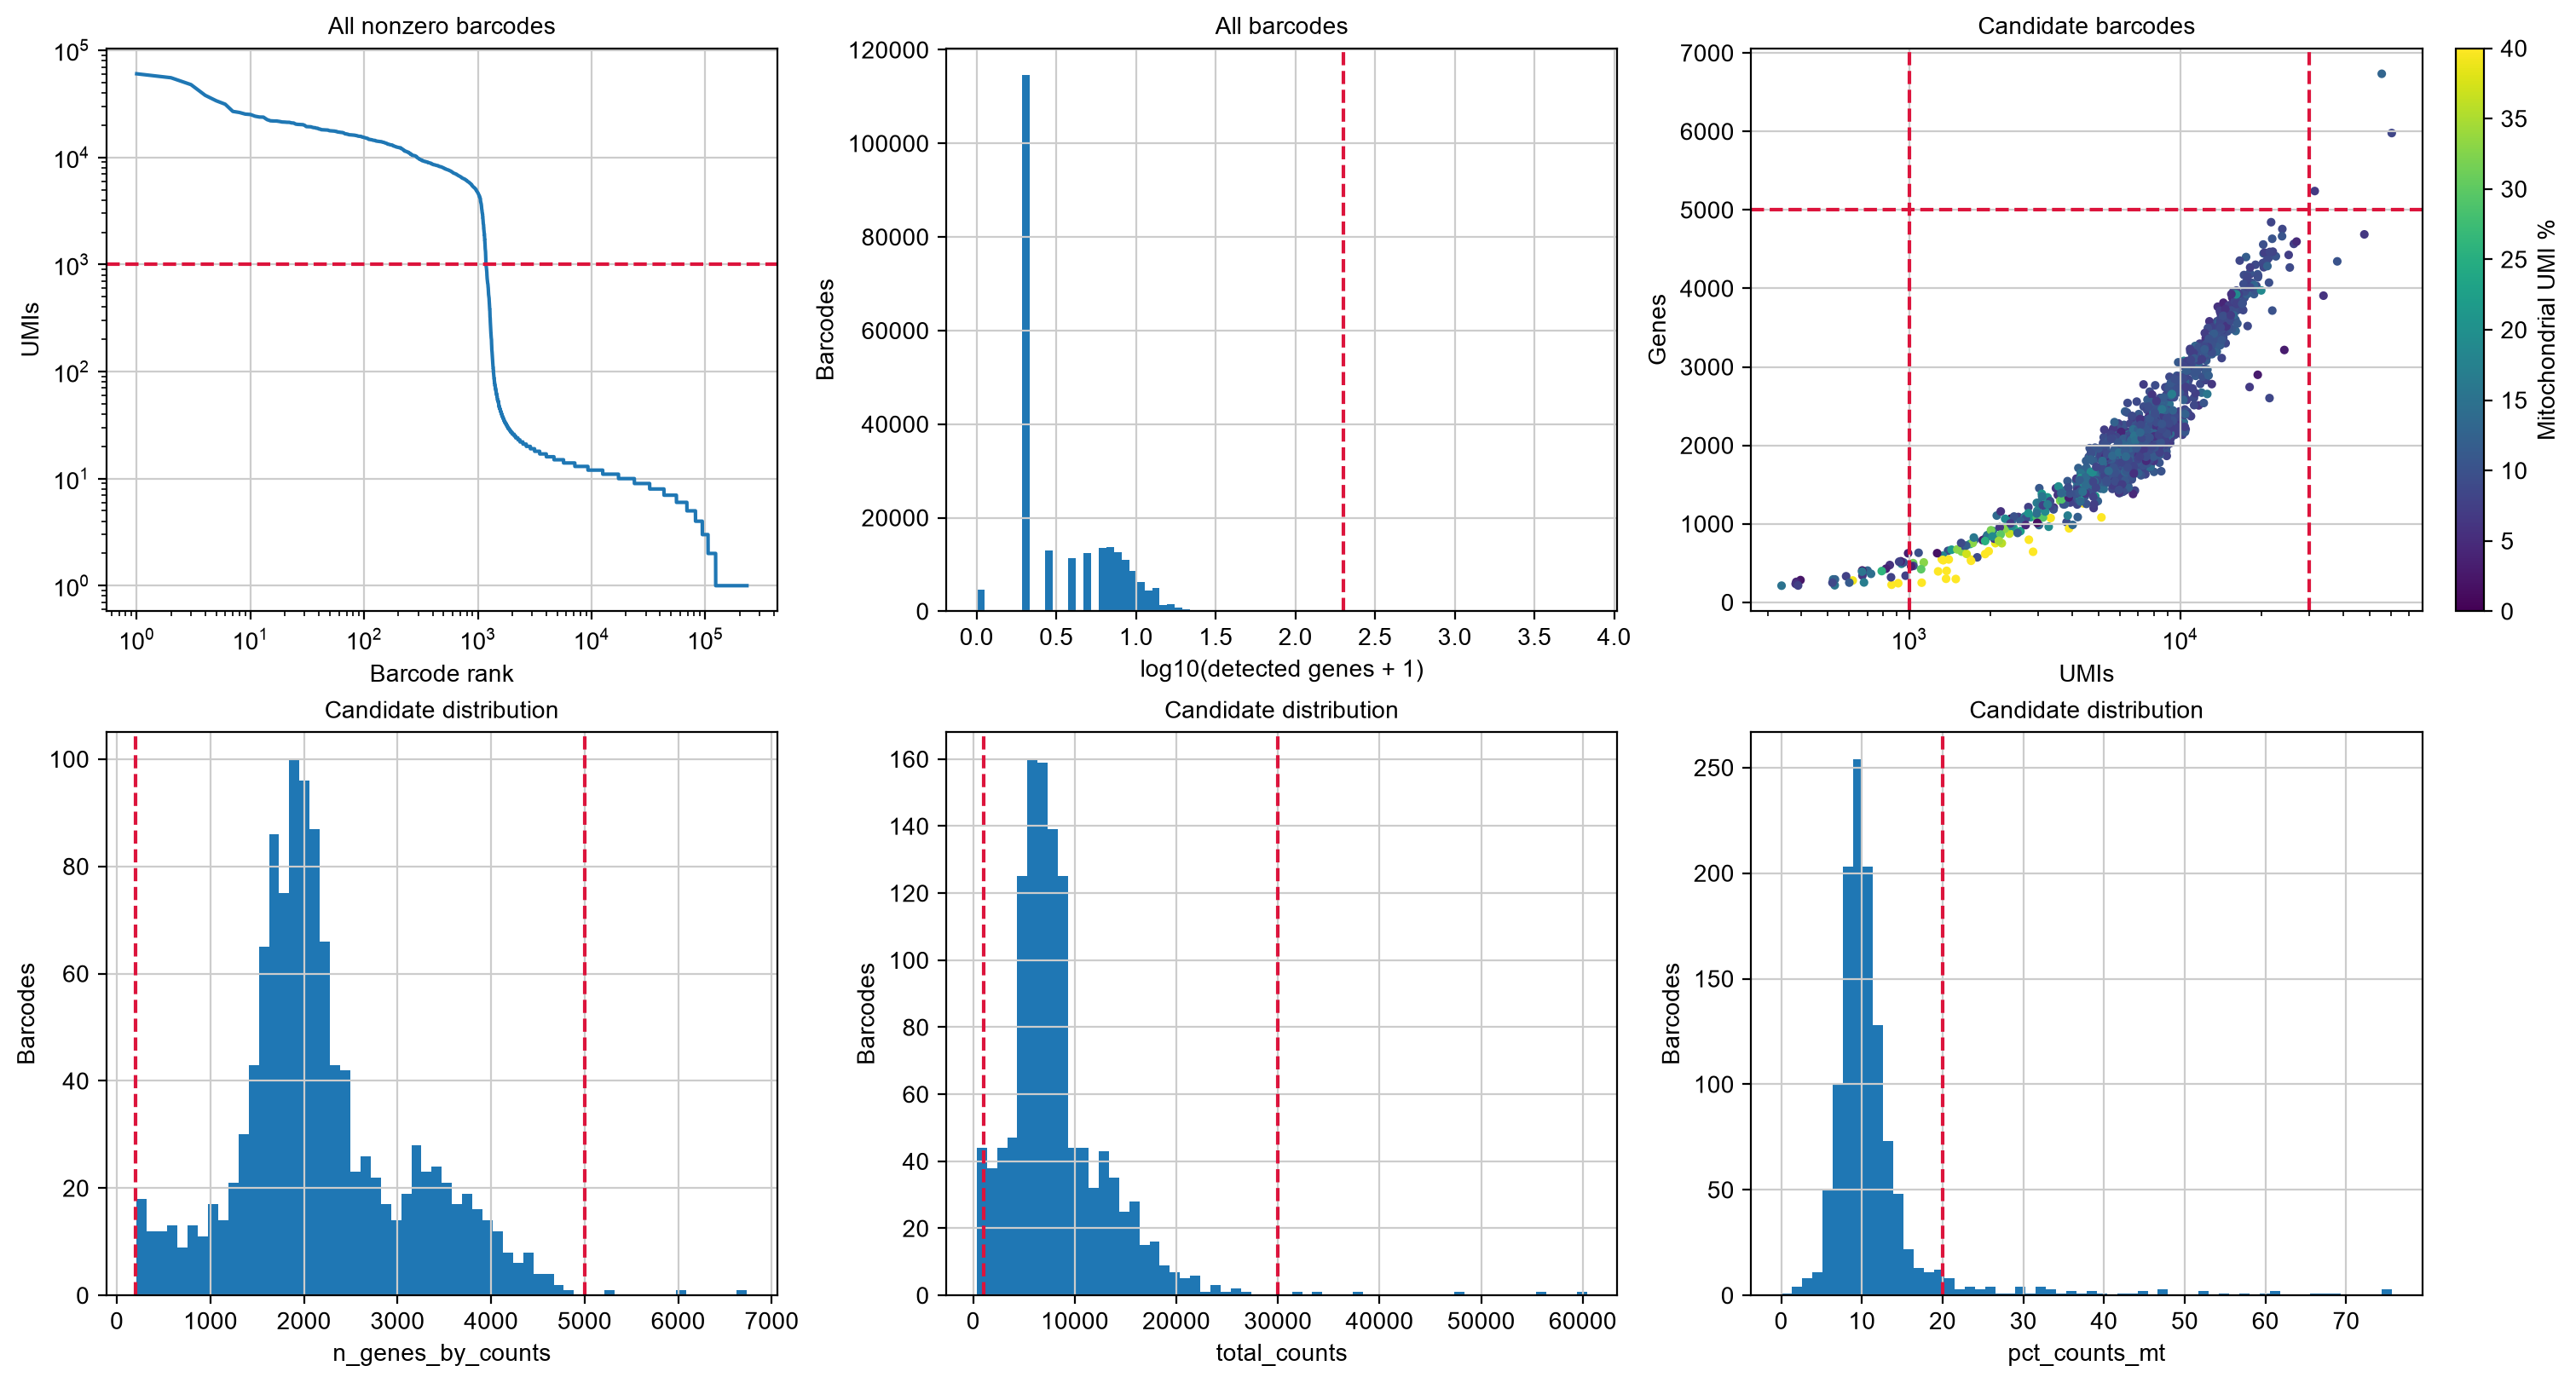

In [3]:
adata.var['mt'] = adata.var.gene_symbol.str.startswith('MT-')
assert int(adata.var.mt.sum()) > 0, 'No mitochondrial symbols found: inspect gene mapping.'
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
qc_columns = ['n_genes_by_counts', 'total_counts', 'pct_counts_mt']
qc = adata.obs[qc_columns].copy()
candidates = qc[qc.n_genes_by_counts >= P['qc_min_genes']]
display(candidates.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))
print(f'{len(qc):,} barcodes; {len(candidates):,} preliminary candidates; '
      f'{int(adata.var.mt.sum())} mitochondrial features.')

fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
ranked = np.sort(qc.total_counts.to_numpy())[::-1]
positive = ranked[ranked > 0]
axes[0, 0].loglog(np.arange(1, len(positive) + 1), positive)
axes[0, 0].axhline(P['qc_min_counts'], color='crimson', ls='--')
axes[0, 0].set(xlabel='Barcode rank', ylabel='UMIs', title='All nonzero barcodes')
axes[0, 1].hist(np.log10(qc.n_genes_by_counts + 1), bins=80)
axes[0, 1].axvline(np.log10(P['qc_min_genes'] + 1), color='crimson', ls='--')
axes[0, 1].set(xlabel='log10(detected genes + 1)', ylabel='Barcodes', title='All barcodes')
points = axes[0, 2].scatter(candidates.total_counts, candidates.n_genes_by_counts,
                          c=candidates.pct_counts_mt, s=7, cmap='viridis', vmin=0, vmax=40)
axes[0, 2].set(xscale='log', xlabel='UMIs', ylabel='Genes', title='Candidate barcodes')
for limit in [P['qc_min_counts'], P['qc_max_counts']]:
    axes[0, 2].axvline(limit, color='crimson', ls='--')
axes[0, 2].axhline(P['qc_max_genes'], color='crimson', ls='--')
fig.colorbar(points, ax=axes[0, 2], label='Mitochondrial UMI %')
for axis, metric, limits in zip(axes[1], qc_columns,
        [[P['qc_min_genes'], P['qc_max_genes']],
         [P['qc_min_counts'], P['qc_max_counts']], [P['qc_max_pct_mt']]]):
    axis.hist(candidates[metric].dropna(), bins=60)
    for limit in limits: axis.axvline(limit, color='crimson', ls='--')
    axis.set(xlabel=metric, ylabel='Barcodes', title='Candidate distribution')
fig.savefig(FIG / '01_qc_before.png', dpi=160)
plt.show()

### Choose thresholds from these distributions

In this full-sample run, the count-rank curve drops steeply near 1,200 barcodes.
The candidate population centers near 2,000 genes and 7,000 UMIs. Its median
mitochondrial fraction is about 10%, with a long tail past 20%.

Our working cutoffs are **200–5,000 detected genes**, **1,000–30,000 UMIs**, and
**mitochondrial UMIs ≤20%**. The lower count threshold lies near the barcode-rank
transition; the gene floor removes very low-complexity profiles. Upper limits
exclude a few extreme libraries. They flag potential multiplets but do not prove
doublet status. The mitochondrial limit removes the tail without discarding the
main population as a 5% cutoff would here. A gene must occur in at least **3 retained
cells** for the analysis, reducing nearly uninformative features.

These are starting decisions for this sample, not universal PBMC rules. The table
below varies the count and mitochondrial cutoffs while keeping other criteria fixed.
If you change the configuration, rerun from the setup cell and reassess the plots;
do not force the retained cell count to equal the vendor's 1,222-cell estimate.

In [4]:
sensitivity = []
for minimum in [P['qc_min_counts'] / 2, P['qc_min_counts'], P['qc_min_counts'] * 2]:
    for maximum_mt in [P['qc_max_pct_mt'] / 2, P['qc_max_pct_mt'] * 0.75, P['qc_max_pct_mt']]:
        keep = (qc.n_genes_by_counts.between(P['qc_min_genes'], P['qc_max_genes'])
                & qc.total_counts.between(minimum, P['qc_max_counts'])
                & qc.pct_counts_mt.le(maximum_mt))
        sensitivity.append({'minimum_UMIs': minimum, 'maximum_mt_percent': maximum_mt,
                            'retained_barcodes': int(keep.sum())})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.pivot(index='minimum_UMIs', columns='maximum_mt_percent',
                          values='retained_barcodes'))
sensitivity.to_csv(OUT / 'qc_threshold_sensitivity.csv', index=False)

maximum_mt_percent,10.0,15.0,20.0
minimum_UMIs,,,
500.0,591,1069,1129
1000.0,579,1051,1107
2000.0,569,1039,1092


## 3 · Apply cell and gene filters, recording every decision

Each QC criterion is stored separately so excluded barcodes remain auditable.
Reported failure counts can overlap; the sequential table shows the cumulative
effect. We keep a full-gene copy of the retained cells for CellTypist, which benefits
from measured zero-expression features as well as expressed genes. The main analysis
then removes genes expressed in fewer than three retained cells. QC metrics remain
those measured before gene filtering, so changing the gene set does not move the QC goalposts.

,step,remaining
0,all barcodes,237012
1,genes_in_range,1201
2,counts_in_range,1167
3,mitochondrial_in_range,1107


filtered out 21928 genes that are detected in less than 3 cells


Analysis retains 1,107 cells × 17,581 genes.


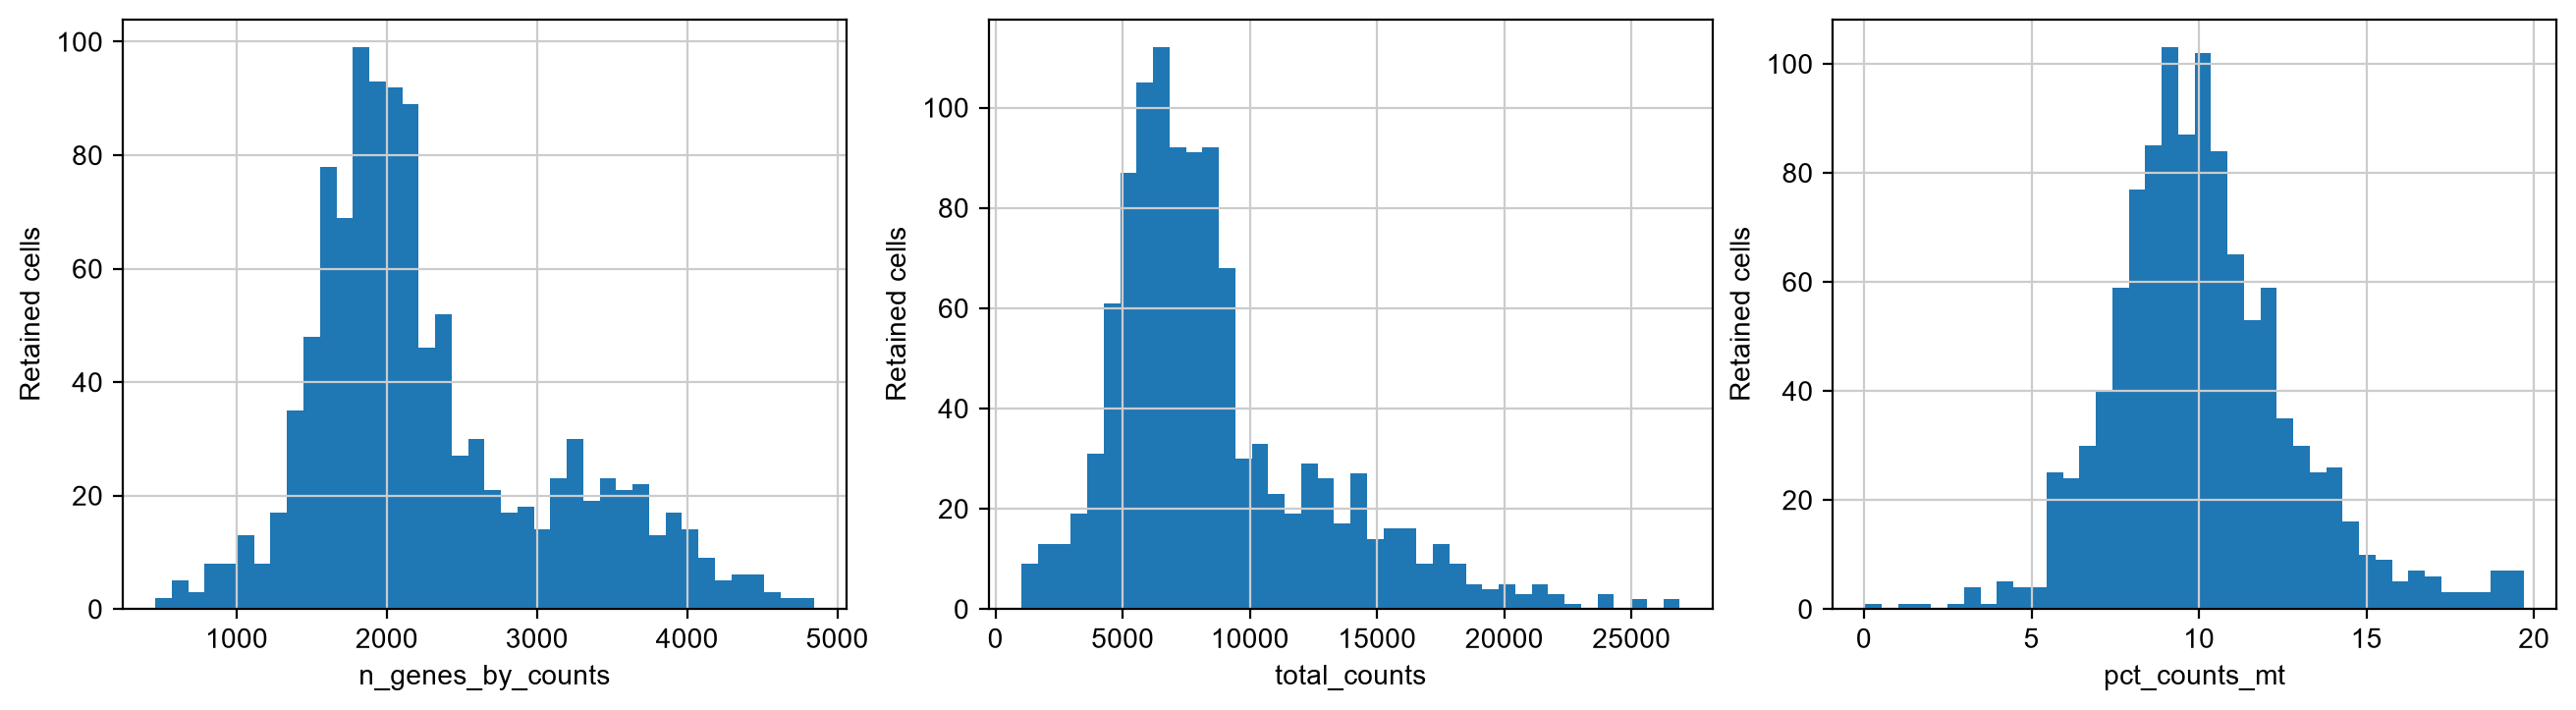

In [5]:
criteria = pd.DataFrame({
    'genes_in_range': qc.n_genes_by_counts.between(P['qc_min_genes'], P['qc_max_genes']),
    'counts_in_range': qc.total_counts.between(P['qc_min_counts'], P['qc_max_counts']),
    'mitochondrial_in_range': qc.pct_counts_mt.le(P['qc_max_pct_mt']),
}, index=qc.index)
qc['pass_qc'] = criteria.all(axis=1)
qc.join(criteria).to_csv(OUT / 'barcode_qc.csv.gz')
remaining = pd.Series(True, index=qc.index)
steps = [{'step': 'all barcodes', 'remaining': len(qc)}]
for column in criteria:
    remaining &= criteria[column]
    steps.append({'step': column, 'remaining': int(remaining.sum())})
display(pd.DataFrame(steps))
adata = adata[qc.pass_qc].copy()
annotation_input = adata.copy()  # all mapped features, before the rare-gene filter
sc.pp.filter_genes(adata, min_cells=P['qc_gene_min_cells'])
assert adata.n_obs > P['neighbors_n_neighbors'] and adata.n_vars > P['hvg_n_top_genes']
adata.layers['counts'] = adata.X.copy()
print(f'Analysis retains {adata.n_obs:,} cells × {adata.n_vars:,} genes.')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
for axis, metric in zip(axes, qc_columns):
    axis.hist(adata.obs[metric], bins=40)
    axis.set(xlabel=metric, ylabel='Retained cells')
fig.savefig(FIG / '02_qc_after.png', dpi=160)
plt.show()

## 4 · Normalize library size, then log-transform

For each cell, `normalize_total(target_sum=10000)` rescales the sum of its gene
counts to 10,000 (CP10k). `log1p` computes `log(1 + CP10k)`, compressing the dynamic
range while retaining zeros. This is also the input scale required by CellTypist.
It adjusts library size, not batch effects or every biological confounder.

`layers['counts']` stays raw. `.X` and `.raw.X` hold normalized expression for the
retained analysis genes; **AnnData's `.raw` name does not mean raw counts** here.
The separate full-gene annotation input is normalized independently using its own
full library totals and is never restricted to HVGs. A single donor needs no
between-sample integration in this notebook.

In [6]:
sc.pp.normalize_total(adata, target_sum=P['normalization_target'])
sc.pp.log1p(adata)
adata.raw = adata.copy()
sc.pp.normalize_total(annotation_input, target_sum=P['normalization_target'])
sc.pp.log1p(annotation_input)
def recovered_totals(matrix):
    inverse = matrix.copy()
    inverse.data = np.expm1(inverse.data)
    return np.asarray(inverse.sum(axis=1)).ravel()
assert np.allclose(recovered_totals(adata.X), P['normalization_target'], rtol=1e-5)
assert np.allclose(recovered_totals(annotation_input.X), P['normalization_target'], rtol=1e-5)
print('Both expression representations sum to 10,000 per cell before log1p.')

normalizing counts per cell


    finished (0:00:00)


normalizing counts per cell


    finished (0:00:00)


Both expression representations sum to 10,000 per cell before log1p.


## 5a · Highly variable genes and PCA

We select up to **2,000 HVGs** using the `seurat` dispersion method on log-normalized
expression. This is a practical starting size for ~1,000 PBMCs. Mitochondrial HVGs
are excluded from PCA so that residual mitochondrial variation does not dominate
the graph. All analysis genes remain available for markers and gene search.

Only the HVG copy is scaled to unit variance and clipped at 10 standard deviations,
limiting the influence of extreme values. Densifying ~1,100 × 2,000 values is modest;
we never densify the original unfiltered matrix. PCA computes 50 components so we
can inspect the elbow before choosing how many to use for neighbors. We do not
regress out counts or mitochondrial percentage automatically: that can remove biology.

extracting highly variable genes


    finished (0:00:00)


HVGs used for PCA: 1998


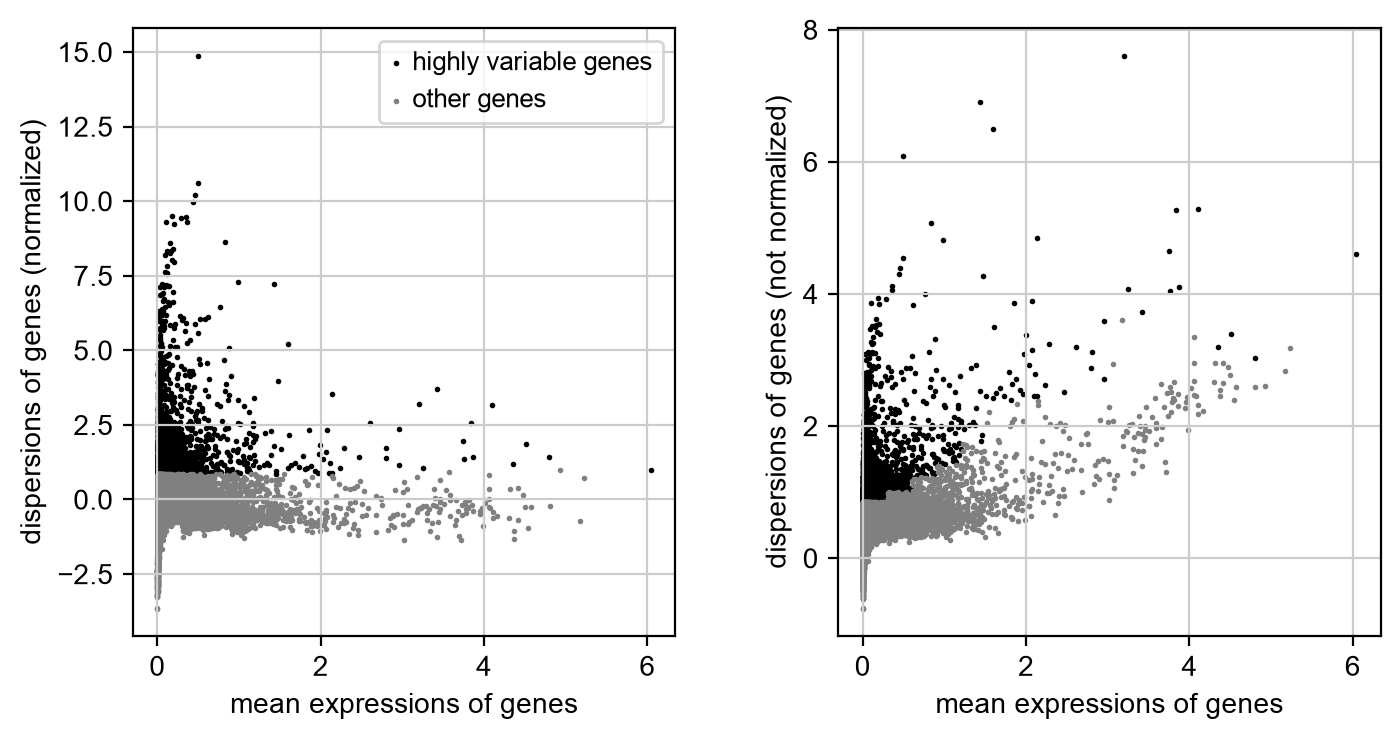

computing PCA


    with n_comps=50


/Users/aaliyahsayed/Desktop/rna-seq/work/envs/stage2/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:00)


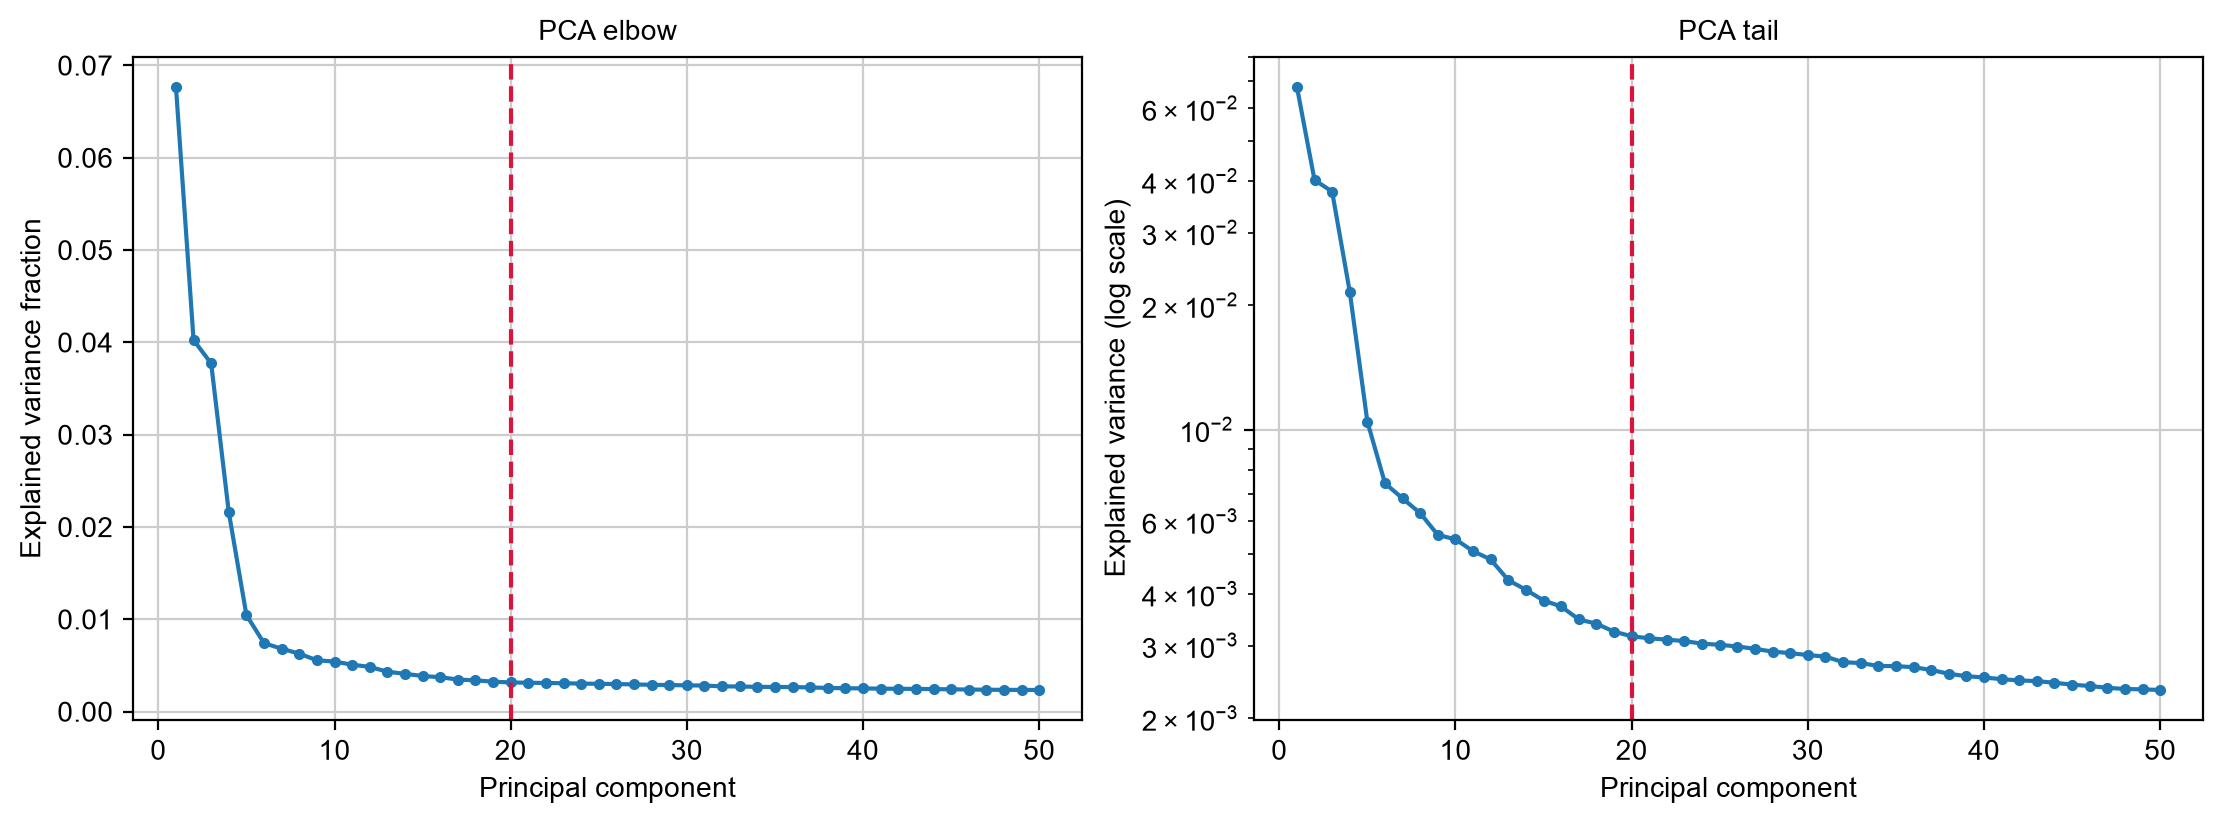

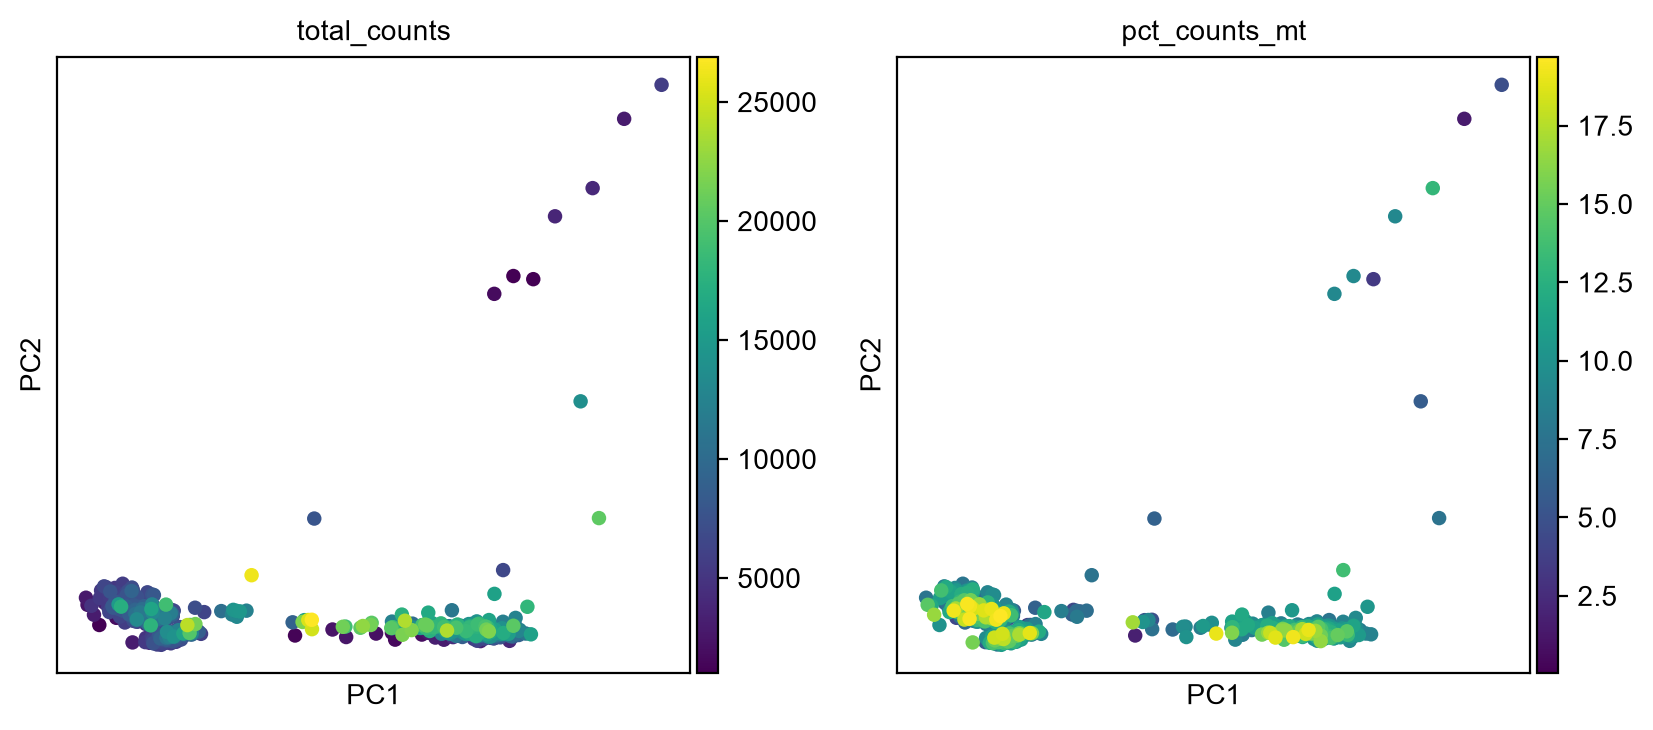

In [7]:
sc.pp.highly_variable_genes(adata, flavor=P['hvg_flavor'], n_top_genes=P['hvg_n_top_genes'])
adata.var['highly_variable'] &= ~adata.var['mt']
print('HVGs used for PCA:', int(adata.var.highly_variable.sum()))
sc.pl.highly_variable_genes(adata, show=False)
plt.savefig(FIG / '03_hvgs.png', dpi=160, bbox_inches='tight')
plt.show()
hvg = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(hvg, max_value=P['pca_scale_clip'])
n_components = min(P['pca_components'], hvg.n_obs - 1, hvg.n_vars - 1)
sc.tl.pca(hvg, n_comps=n_components, svd_solver='arpack', random_state=P['seed'])
adata.obsm['X_pca'] = hvg.obsm['X_pca'].copy()
adata.uns['pca'] = hvg.uns['pca'].copy()
adata.varm['PCs'] = np.zeros((adata.n_vars, n_components), dtype=np.float32)
adata.varm['PCs'][adata.var.highly_variable.to_numpy(), :] = hvg.varm['PCs']
variance = pd.DataFrame({'PC': np.arange(1, n_components + 1),
                         'variance_ratio': adata.uns['pca']['variance_ratio']})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].plot(variance.PC, variance.variance_ratio, 'o-', markersize=3)
axes[0].set(xlabel='Principal component', ylabel='Explained variance fraction', title='PCA elbow')
axes[1].semilogy(variance.PC, variance.variance_ratio, 'o-', markersize=3)
axes[1].set(xlabel='Principal component', ylabel='Explained variance (log scale)', title='PCA tail')
for axis in axes: axis.axvline(P['neighbors_n_pcs'], color='crimson', ls='--')
fig.savefig(FIG / '04_pca_elbow.png', dpi=160)
plt.show()
variance.to_csv(OUT / 'pca_variance.csv', index=False)
sc.pl.pca(adata, color=['total_counts', 'pct_counts_mt'], show=False)
plt.savefig(FIG / '05_pca_qc.png', dpi=160, bbox_inches='tight')
plt.show()
del hvg

## 5b · Build the neighbor graph

We start with **20 PCs** and **15 neighbors**: enough dimensions to retain several
immune lineages while avoiding the weakest PCA tail, and a neighborhood small
relative to ~1,100 cells. Inspect the elbow above; the marked cutoff is a modeling
choice, not a formally optimal dimension. The graph measures local similarity in
PCA space; UMAP will visualize this graph, not the original high-dimensional counts.

In the observed run the steepest bend is around PCs 5–6, followed by a
shallower tail. Keeping 20 deliberately goes beyond the first elbow to retain
subtler immune-state variation; it is not an assertion that PC20 is a sharp elbow.

In [8]:
assert P['neighbors_n_pcs'] <= n_components
sc.pp.neighbors(adata, n_neighbors=P['neighbors_n_neighbors'],
                n_pcs=P['neighbors_n_pcs'], use_rep='X_pca', random_state=P['seed'])
print('Variance in selected PCs:',
      round(float(variance.variance_ratio.iloc[:P['neighbors_n_pcs']].sum()), 3))

computing neighbors


    finished (0:00:03)


Variance in selected PCs: 0.248


## 6 · Leiden communities and UMAP

Leiden partitions the neighbor graph. Resolution **0.6** is an initial moderate
granularity; cluster IDs are arbitrary and are not cell types. We use Scanpy's
igraph implementation with an undirected graph and two iterations, and save the seed.
UMAP's `min_dist=0.3` allows visible neighborhoods without making every group extremely
tight. UMAP distances between distant islands are not quantitative lineage distances.
QC-colored panels help reveal residual quality gradients or suspicious clusters.

running Leiden clustering


    finished (0:00:00)


computing UMAP


    finished (0:00:01)


,cells
leiden,
0,115
1,126
2,76
3,174
4,57
5,208
6,38
7,68
8,57


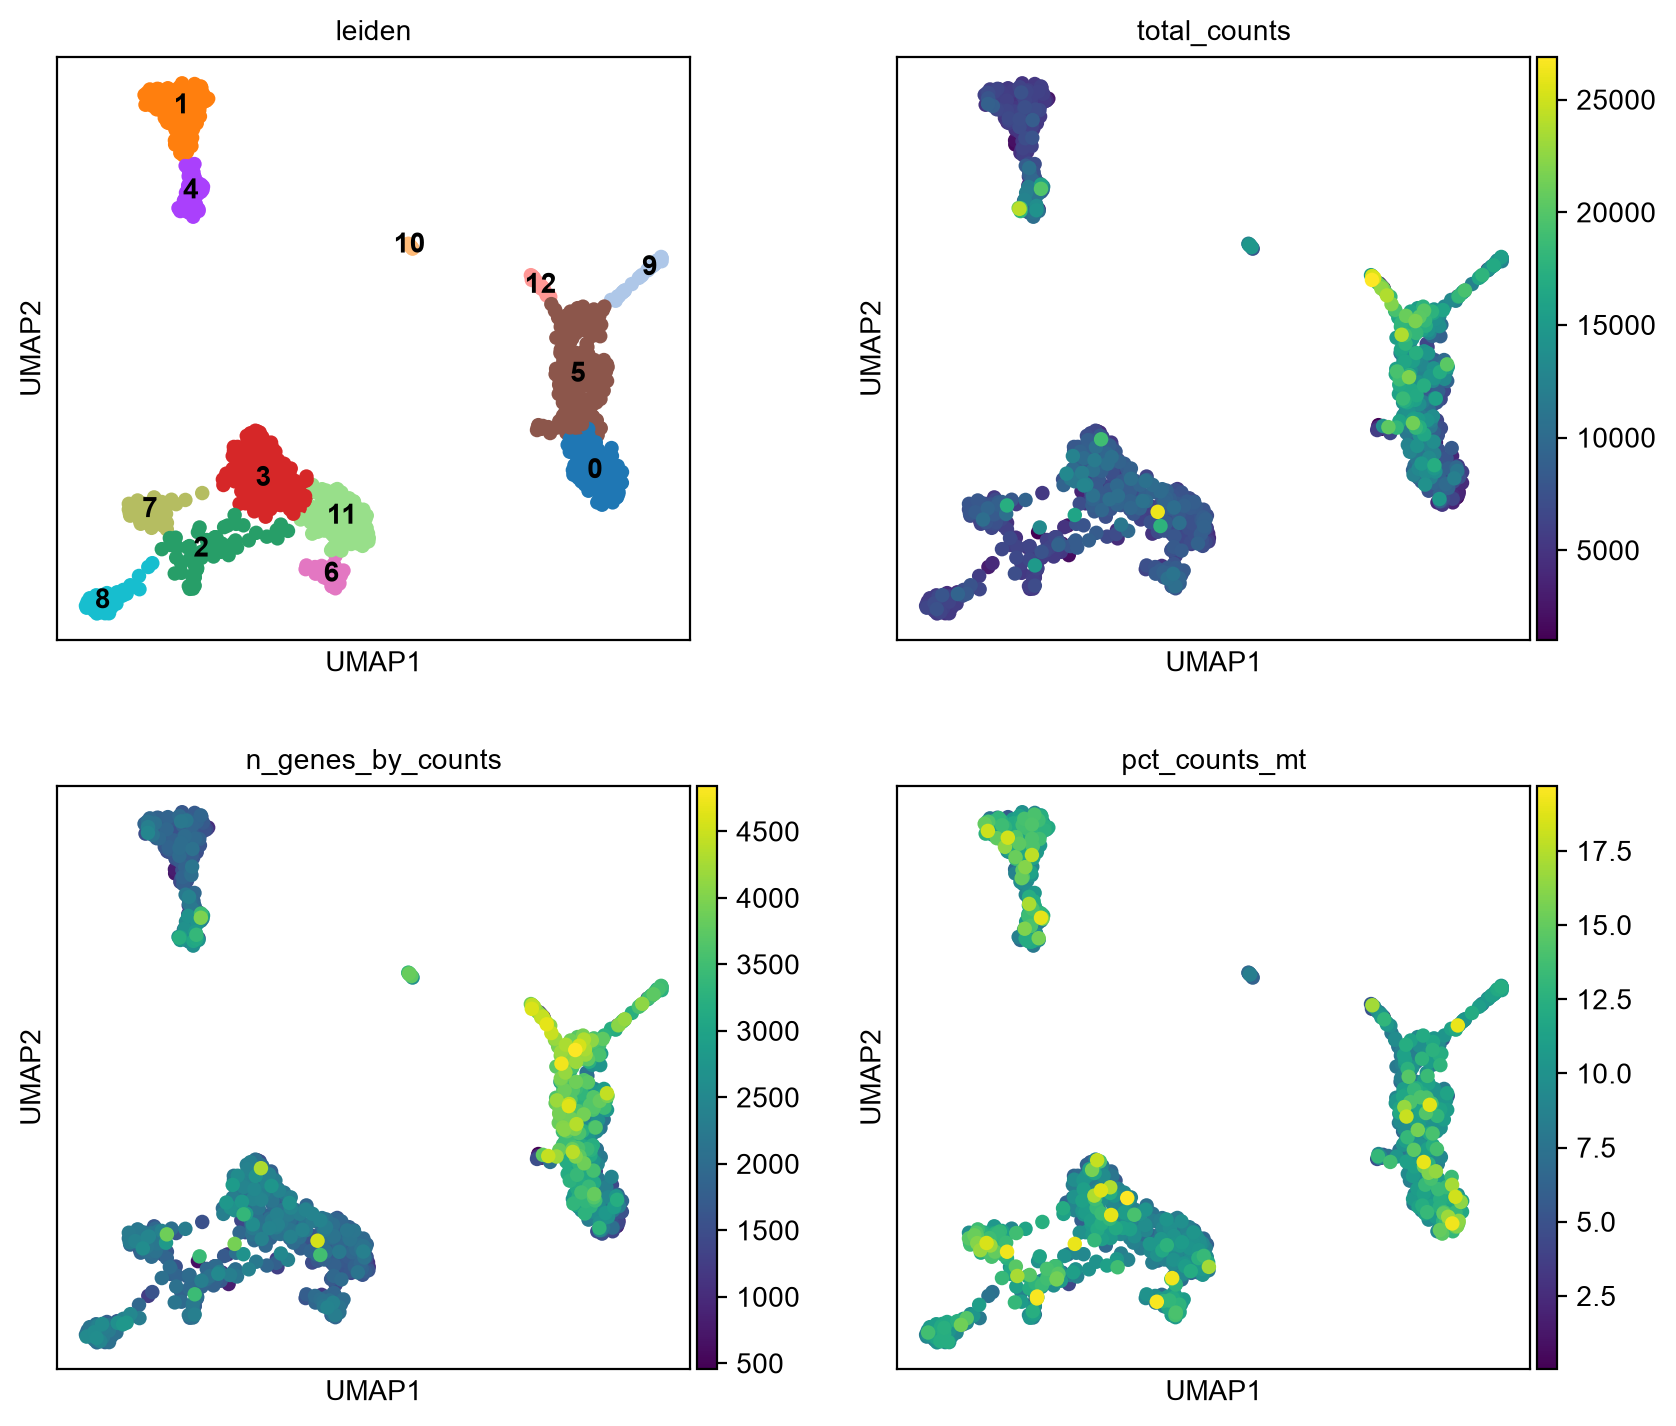

In [9]:
sc.tl.leiden(adata, resolution=P['leiden_resolution'], random_state=P['seed'],
             flavor='igraph', directed=False, n_iterations=P['leiden_iterations'], key_added='leiden')
sc.tl.umap(adata, min_dist=P['umap_min_dist'], random_state=P['seed'])
display(adata.obs.leiden.value_counts(sort=False).rename('cells').to_frame())
sc.pl.umap(adata, color=['leiden', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt'],
           ncols=2, legend_loc='on data', show=False)
plt.savefig(FIG / '06_umap_clusters_qc.png', dpi=160, bbox_inches='tight')
plt.show()

## 7 · Rank cluster markers and plot them

We compare each cluster with all other cells using a **Wilcoxon rank-sum test**
on log-normalized expression, with tie correction and Benjamini–Hochberg adjustment.
We test all retained genes, not just HVGs. The top four positive-score markers per
cluster are shown as a dot plot: dot size is the fraction of cells expressing the
gene and color is mean expression, scaled per gene for display.

These are descriptive cluster markers. Clustering and testing use the same cells,
and this is one donor, so the p-values are not independent biological validation
or evidence of differential expression between experimental conditions.

ranking genes


    finished (0:00:01)


,group,names,scores,logfoldchanges,pvals_adj
0,0,S100A12,20.449635,5.486023,1.064108e-88
1,0,RBP7,19.867506,4.058951,5.756468e-84
2,0,S100A8,19.855780,7.142634,5.756468e-84
3,0,VCAN,18.978399,4.744491,1.130955e-76
17581,1,TCL1A,30.871954,9.684175,4.998183e-205
17582,1,IGHD,29.989407,8.221324,1.185717e-193
17583,1,IGHM,27.071398,8.113869,1.253477e-157
17584,1,CD79A,26.001244,6.545568,2.107220e-145
35162,2,CCL5,14.969308,4.867432,2.048677e-46
35163,2,TRGC2,14.840122,4.197945,7.085976e-46


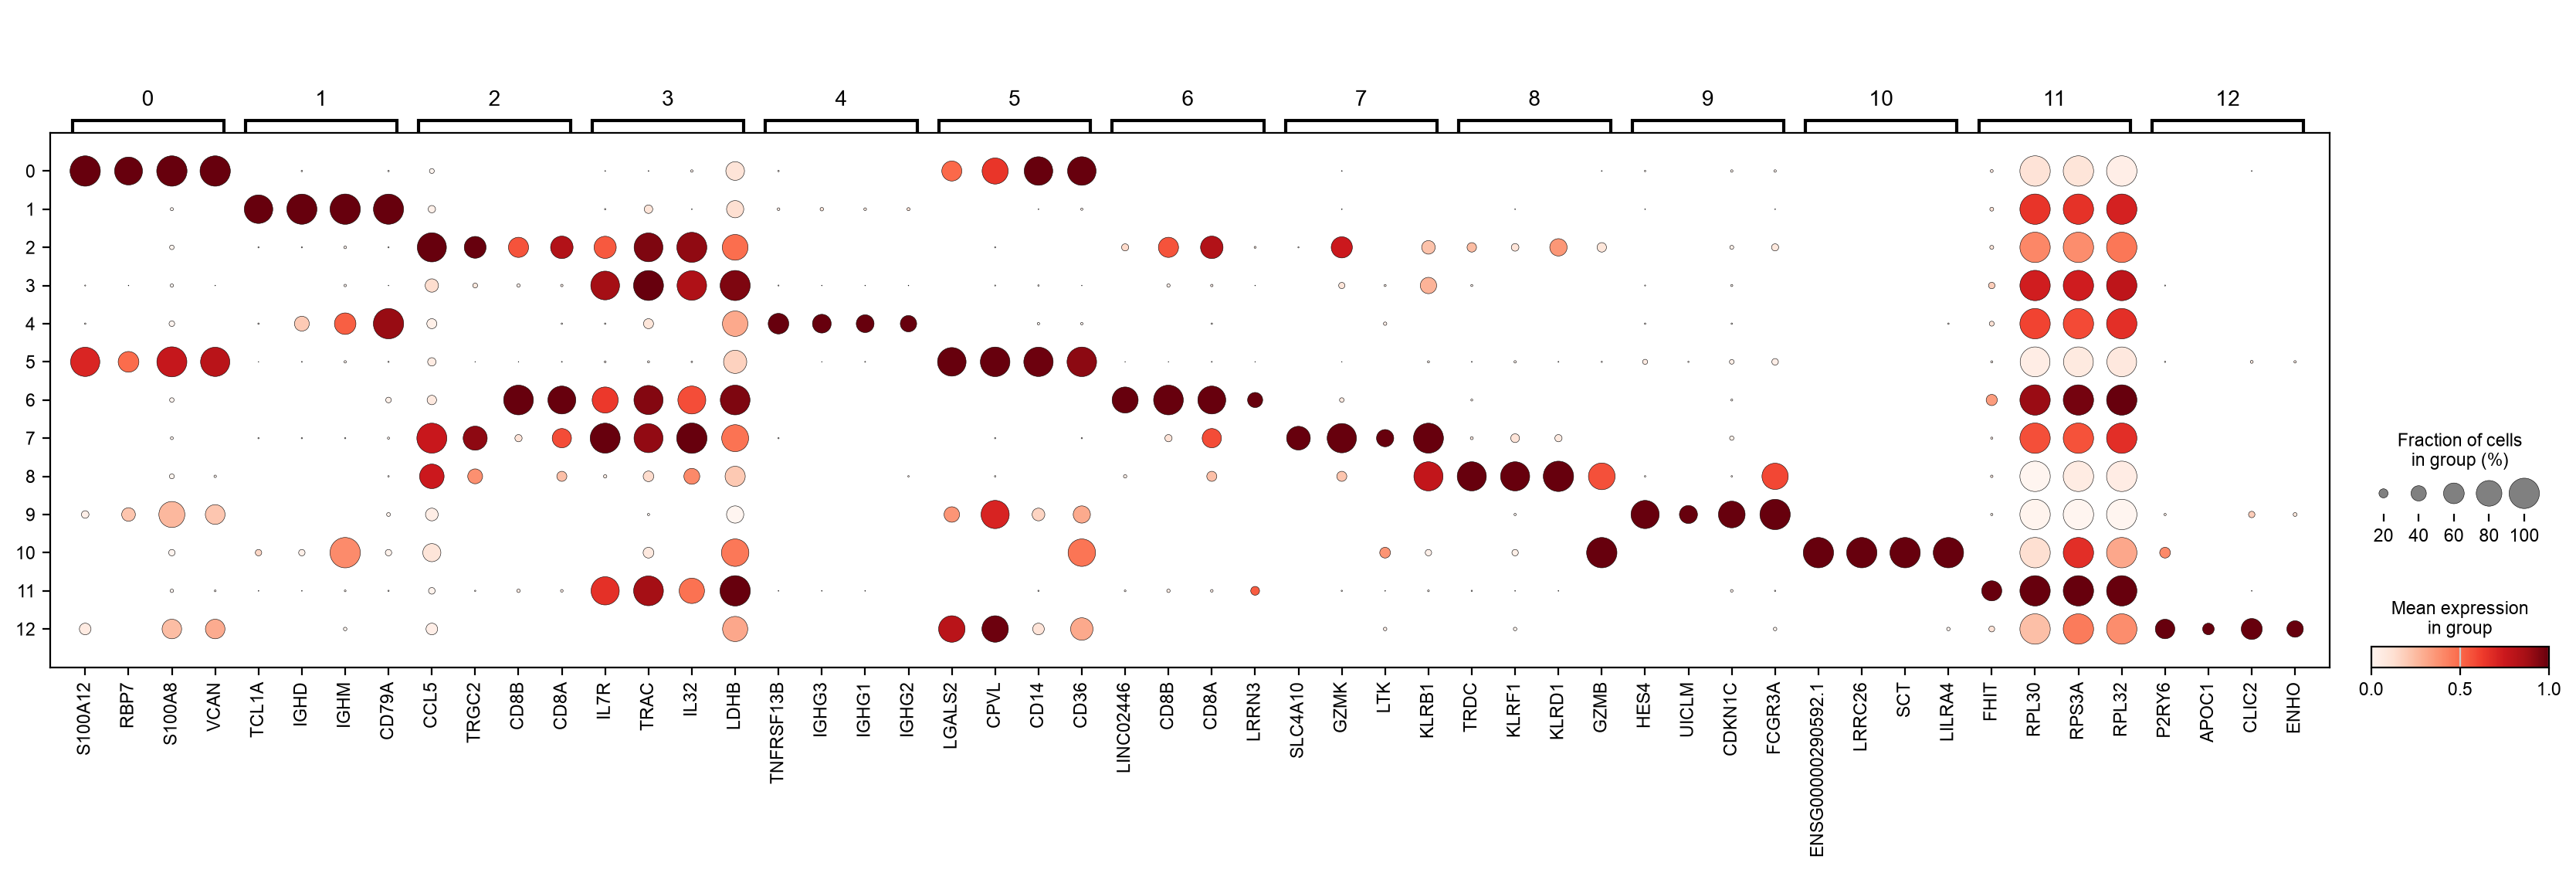

In [10]:
sc.tl.rank_genes_groups(adata, groupby='leiden', method=P['marker_method'],
                        use_raw=True, tie_correct=True, corr_method='benjamini-hochberg', pts=True)
markers = sc.get.rank_genes_groups_df(adata, group=None)
markers['group'] = markers['group'].astype(str)
markers.to_csv(OUT / 'marker_genes_all.csv', index=False)
top_markers = markers[markers.scores > 0].groupby('group', sort=False).head(P['marker_top_n'])
top_markers.to_csv(OUT / 'marker_genes_top.csv', index=False)
display(top_markers[['group', 'names', 'scores', 'logfoldchanges', 'pvals_adj']])
sc.pl.rank_genes_groups_dotplot(adata, n_genes=P['marker_top_n'],
    standard_scale='var', dendrogram=False, show=False)
plt.savefig(FIG / '07_cluster_markers.png', dpi=160, bbox_inches='tight')
plt.show()

## 8 · CellTypist: a reference-based hypothesis plus majority voting

We use the official **Immune_All_Low v2** model, which distinguishes fine immune
subtypes. Its download URL and SHA-256 are pinned in the config; an existing model
must match before it is loaded. Input is full-gene log1p(CP10k) with gene symbols,
including measured zero features, rather than scaled values or only HVGs.

Each cell first receives its best model label. We then over-cluster our graph at
resolution **5.0** to create small local groups and apply CellTypist majority voting.
At least half of a subgroup must support the leading label (`min_prop=0.5`), otherwise
it is marked heterogeneous. These subgroups are intentionally finer than the main
Leiden clusters. We retain both labels and their disagreement so smoothing stays
visible. Model sigmoid scores are reference-dependent scores, not calibrated clinical
probabilities. A dominant label can conceal mixed clusters, so inspect the crosstab.

The score panel shows the original per-cell best score; it is not confidence
in a different label assigned by majority voting.

CellTypist model with 98 cell types and 6639 features
    date: 2022-07-16 00:20:42.927778
    details: immune sub-populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: Age-associated B cells, Alveolar macrophages, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX
Model feature overlap: 5,842/6,639
running Leiden clustering


    finished (0:00:00)


/Users/aaliyahsayed/Desktop/rna-seq/work/envs/stage2/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
🔬 Input data has 1107 cells and 39509 genes


🔗 Matching reference genes in the model


🧬 5842 features used for prediction


⚖️ Scaling input data


... (5 outputs left out)

celltypist_predicted,Age-associated B cells,CD16+ NK cells,CD16- NK cells,Classical monocytes,DC precursor,DC1,DC2,ILC3,MAIT cells,Megakaryocyte precursor,...,Non-classical monocytes,Plasma cells,Regulatory T cells,Tcm/Naive cytotoxic T cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,Trm cytotoxic T cells,pDC
leiden,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,115,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,11,0,...,0,0,2,6,5,1,24,24,1,0
3,0,0,0,0,0,0,0,1,0,0,...,0,0,15,0,101,55,0,2,0,0
4,5,0,0,0,0,0,0,0,0,0,...,0,4,0,0,0,0,0,0,0,0
5,0,0,0,186,0,0,3,0,0,0,...,12,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,36,2,0,0,0,0,0
7,0,0,0,0,0,0,0,0,68,0,...,0,0,0,0,0,0,0,0,0,0
8,0,51,3,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0


**After majority voting**

cell_type,CD16+ NK cells,Classical monocytes,DC2,Heterogeneous,MAIT cells,Memory B cells,Naive B cells,Non-classical monocytes,Tcm/Naive cytotoxic T cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,pDC
leiden,,,,,,,,,,,,,,
0,0,115,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,126,0,0,0,0,0,0,0
2,0,0,0,14,0,0,0,0,0,0,0,21,41,0
3,0,0,0,31,0,0,0,0,0,109,34,0,0,0
4,0,0,0,0,0,56,1,0,0,0,0,0,0,0
5,0,204,4,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,38,0,0,0,0,0
7,0,0,0,0,66,0,0,0,0,0,1,0,1,0
8,57,0,0,0,0,0,0,0,0,0,0,0,0,0


Cells changed by majority voting: 155


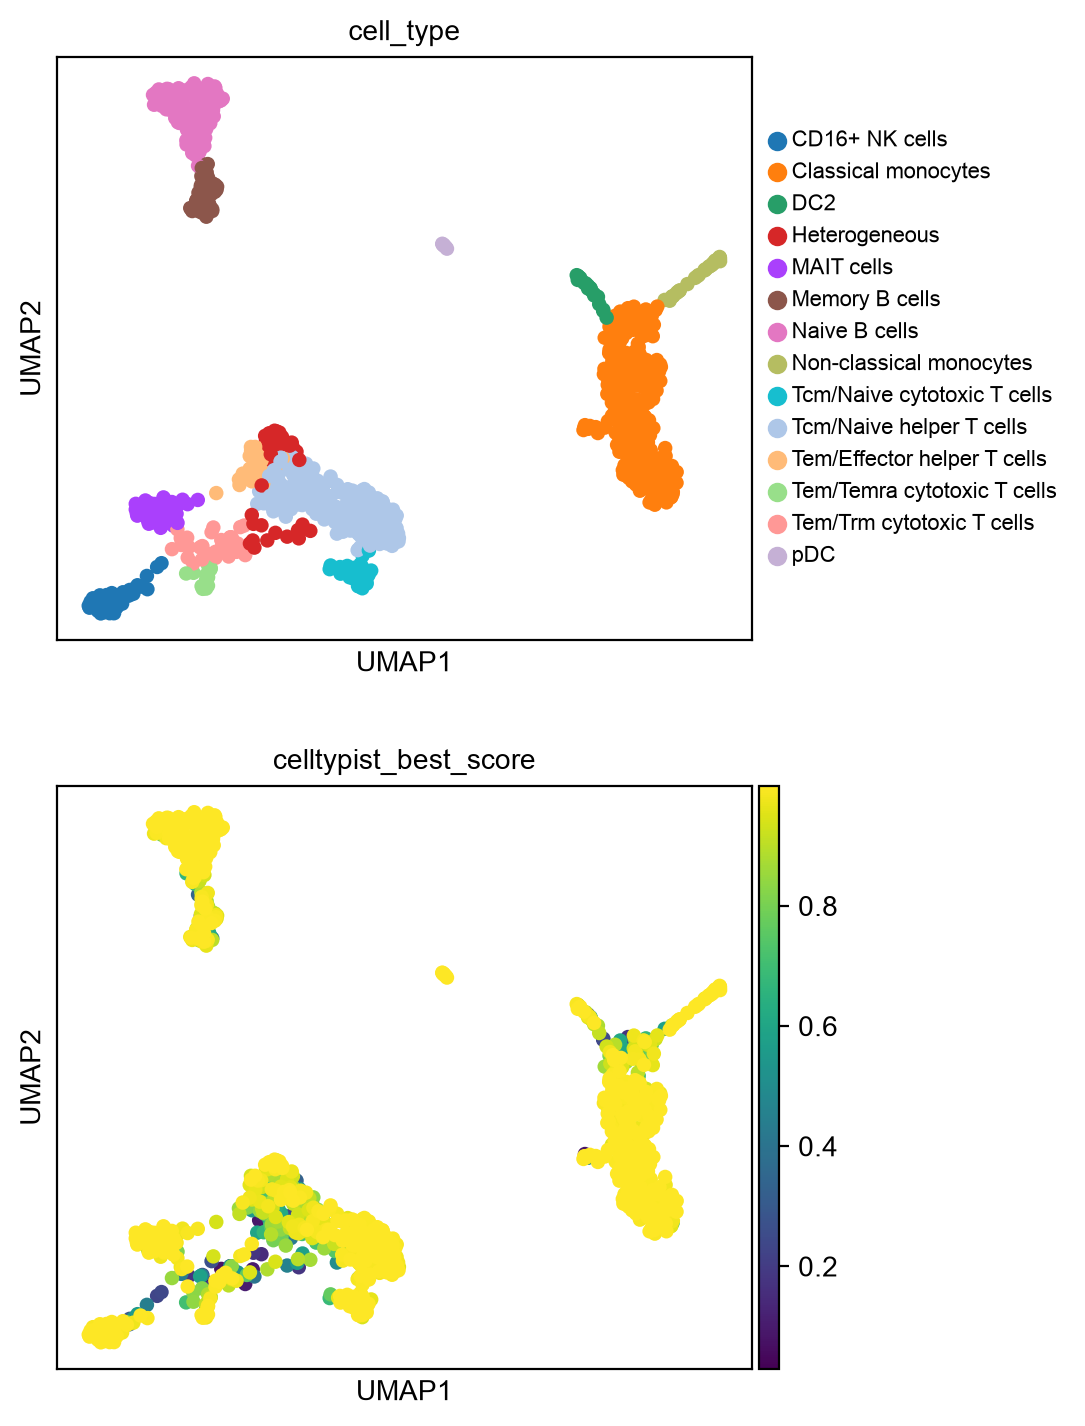

In [11]:
import requests
import celltypist
from celltypist import models

model_path = ROOT / P['celltypist_model']
model_path.parent.mkdir(parents=True, exist_ok=True)
if not model_path.exists():
    response = requests.get(P['celltypist_model_url'], timeout=120)
    response.raise_for_status()
    assert hashlib.sha256(response.content).hexdigest() == P['celltypist_model_sha256']
    temporary = model_path.with_suffix('.download')
    temporary.write_bytes(response.content)
    temporary.replace(model_path)
model_hash = hashlib.sha256(model_path.read_bytes()).hexdigest()
assert model_hash == P['celltypist_model_sha256'], 'Model checksum changed; review before updating.'
model = models.Model.load(str(model_path))
overlap = np.intersect1d(annotation_input.var_names, model.features)
print(model)
print(f'Model feature overlap: {len(overlap):,}/{len(model.features):,}')
assert len(overlap) > 0
sc.tl.leiden(adata, resolution=P['celltypist_overcluster_resolution'], random_state=P['seed'],
             flavor='igraph', directed=False, n_iterations=P['leiden_iterations'],
             key_added='celltypist_overclustering')
assert annotation_input.obs_names.equals(adata.obs_names)
predictions = celltypist.annotate(annotation_input, model=model, majority_voting=True,
    over_clustering=adata.obs['celltypist_overclustering'], min_prop=P['celltypist_min_prop'])
labels = predictions.predicted_labels.reindex(adata.obs_names)
adata.obs['celltypist_predicted'] = labels['predicted_labels'].astype('category')
adata.obs['cell_type'] = labels['majority_voting'].astype('category')
probabilities = predictions.probability_matrix.reindex(adata.obs_names)
adata.obs['celltypist_best_score'] = probabilities.max(axis=1).to_numpy()
adata.obs['celltypist_vote_changed'] = (adata.obs.celltypist_predicted.astype(str)
                                      != adata.obs.cell_type.astype(str))
labels.to_csv(OUT / 'celltypist_labels.csv')
probabilities.to_csv(OUT / 'celltypist_scores.csv')
crosstab = pd.crosstab(adata.obs.leiden, adata.obs.cell_type)
crosstab.to_csv(OUT / 'cluster_celltypist_crosstab.csv')
raw_crosstab = pd.crosstab(adata.obs.leiden, adata.obs.celltypist_predicted)
raw_crosstab.to_csv(OUT / 'cluster_raw_celltypist_crosstab.csv')
display(Markdown('**Before majority voting**'))
display(raw_crosstab)
display(Markdown('**After majority voting**'))
display(crosstab)
print('Cells changed by majority voting:', int(adata.obs.celltypist_vote_changed.sum()))
sc.pl.umap(adata, color=['cell_type', 'celltypist_best_score'], ncols=1,
           legend_fontsize=8, show=False)
plt.savefig(FIG / '08_umap_celltypist.png', dpi=160, bbox_inches='tight')
plt.show()

## 9 · Check labels against known PBMC markers

Interpret combinations rather than a single gene: **CD3E** supports T cells;
**IL7R** with T-cell markers suggests helper/memory-like T cells; **CD8A** can also
occur in NK cells, so inspect CD3E and the cytotoxic genes. **MS4A1/CD79A** support B
cells; **GNLY/NKG7** support cytotoxic populations; **CD14/LYZ** support classical
monocytes. **FCGR3A** occurs in nonclassical monocytes and NK cells, so LYZ/CST3 and
T/NK markers supply context. **FCER1A/CST3** support dendritic cells, although CST3
is broadly myeloid. Missing or absent markers are reported explicitly.

The first dot plot is grouped by unsupervised Leiden cluster; the second uses model
labels. Feature plots show whether a cluster contains distinct marker-positive
subpopulations. The summary includes label agreement, top ranked genes, and voting
changes. Small or mixed groups should retain cautious labels rather than being
forced into a textbook PBMC list.

Missing markers: []


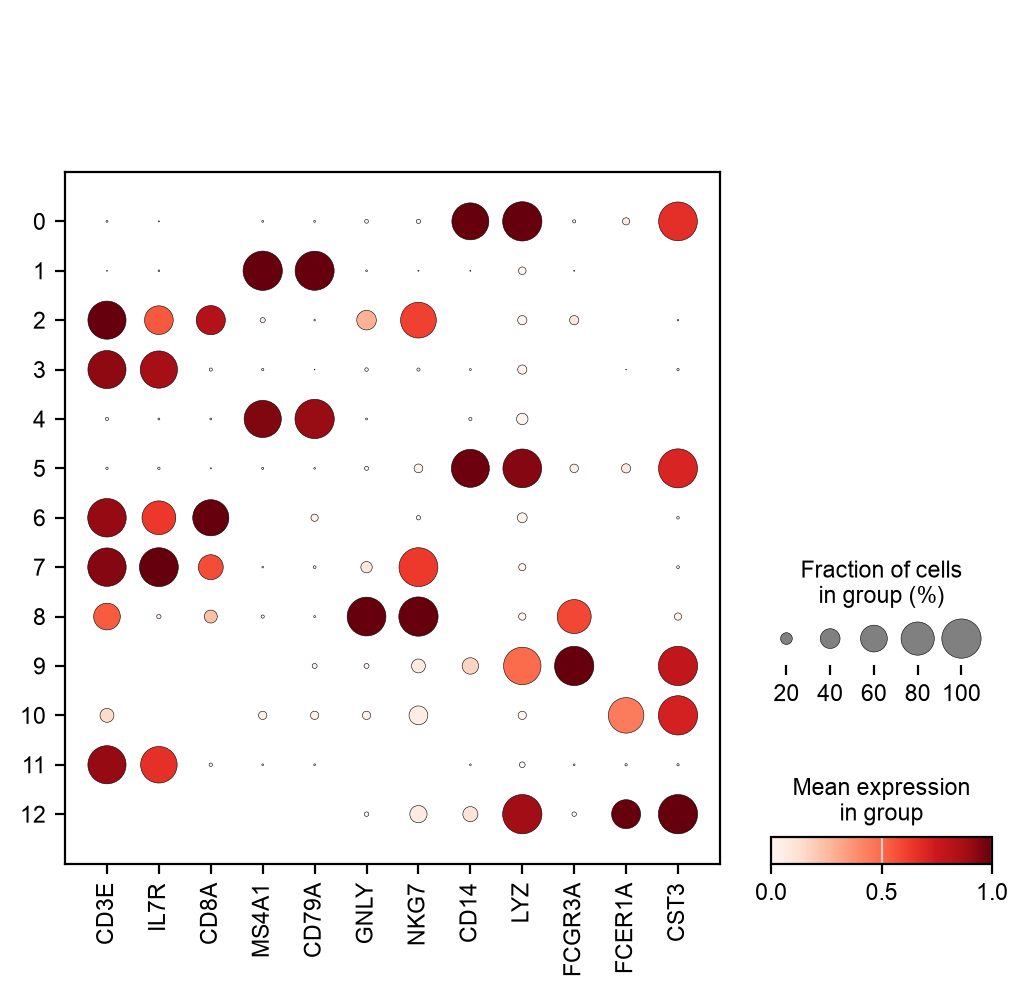

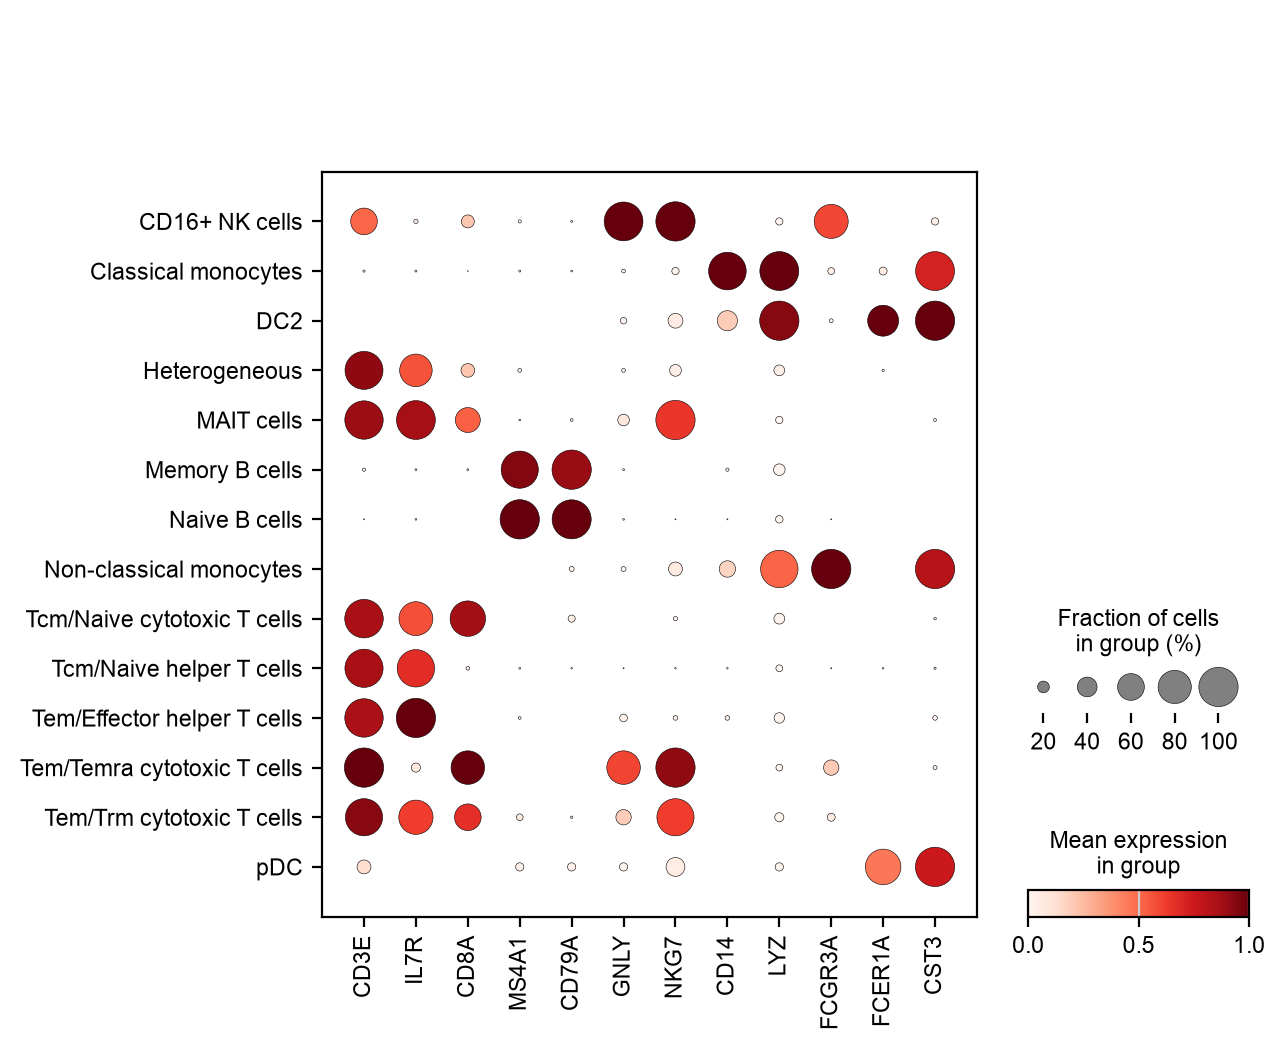

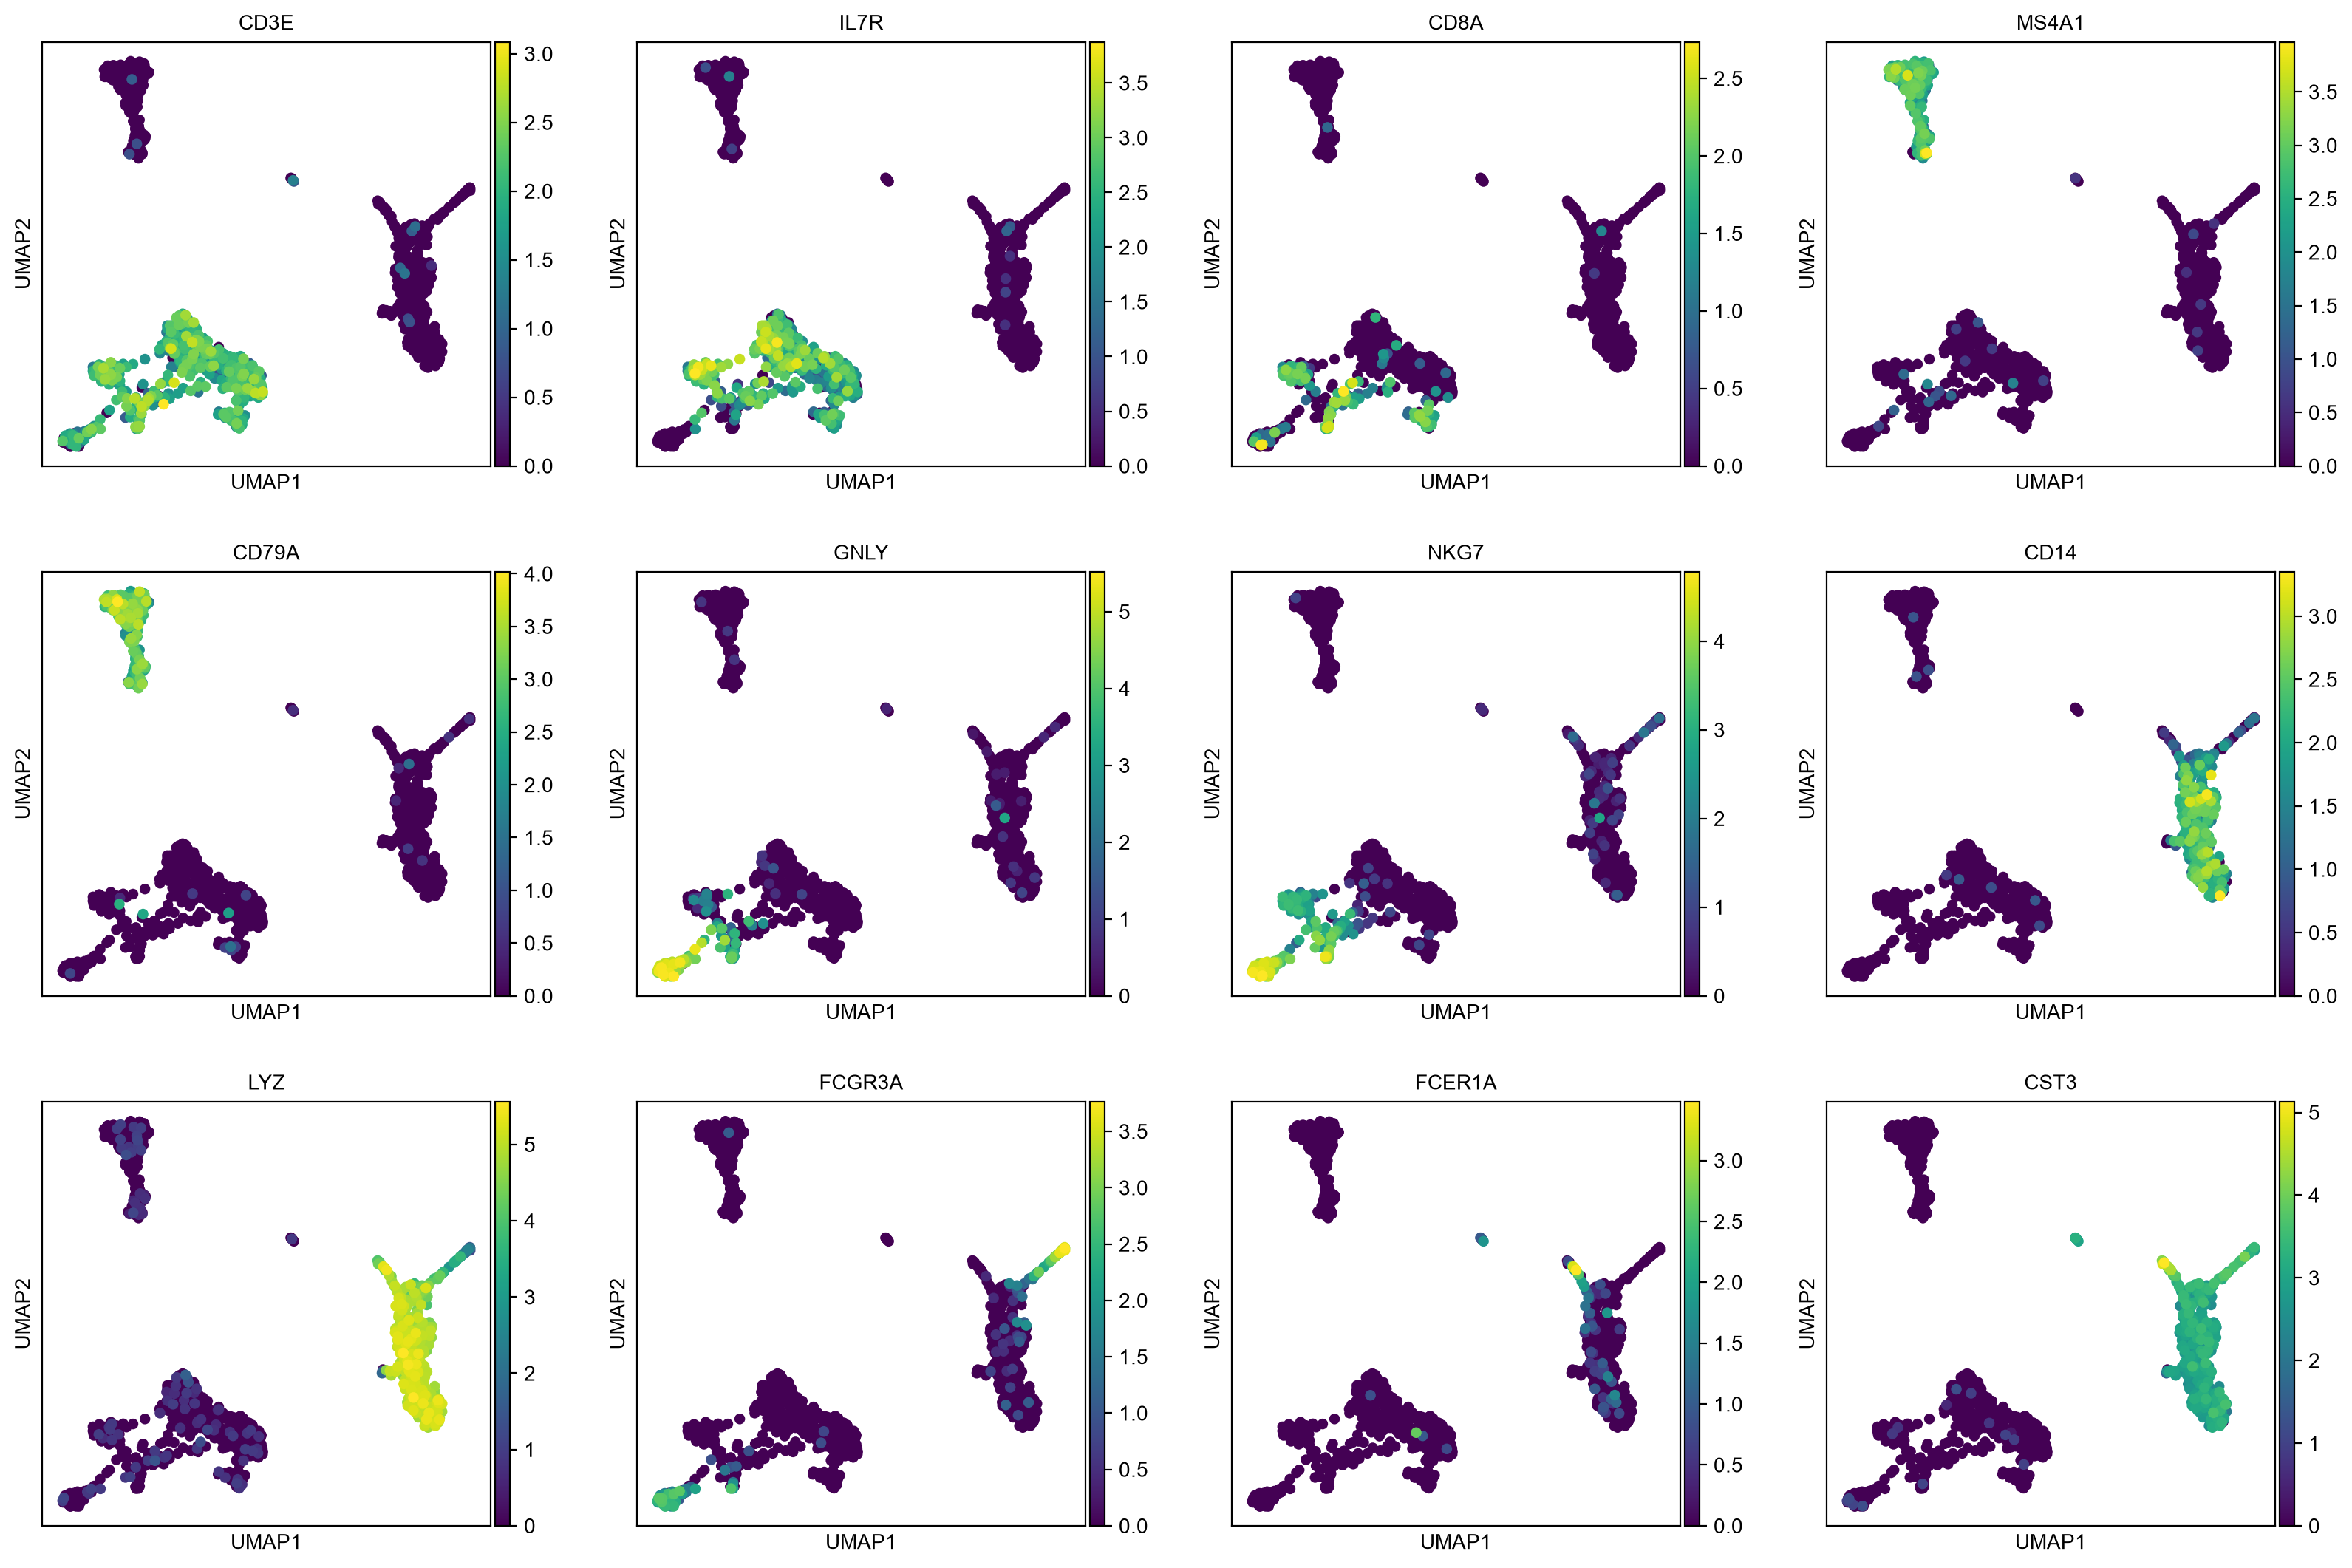

,cluster,cells,dominant_celltypist_label,dominant_label_fraction,median_genes,median_mt_percent,vote_changed_cells,top_markers
0,0,115,Classical monocytes,1.000000,2416.0,10.769231,0,"S100A12, RBP7, S100A8, VCAN, PLBD1, MNDA"
1,1,126,Naive B cells,1.000000,1664.0,10.974384,2,"TCL1A, IGHD, IGHM, CD79A, MS4A1, LINC00926"
2,2,76,Tem/Trm cytotoxic T cells,0.539474,1911.0,10.272310,35,"CCL5, TRGC2, CD8B, CD8A, CST7, NKG7"
3,3,174,Tcm/Naive helper T cells,0.626437,2053.5,8.782190,60,"IL7R, TRAC, IL32, LDHB, CD3D, CD3G"
4,4,57,Memory B cells,0.982456,2208.0,10.366462,10,"TNFRSF13B, IGHG3, IGHG1, IGHG2, SSPN, IGHG4"
5,5,208,Classical monocytes,0.980769,3313.0,9.456274,23,"LGALS2, CPVL, CD14, CD36, TNFAIP2, MS4A6A"
6,6,38,Tcm/Naive cytotoxic T cells,1.000000,1871.5,10.641214,2,"LINC02446, CD8B, CD8A, LRRN3, S100B, PASK"
7,7,68,MAIT cells,0.970588,2021.5,12.470897,2,"SLC4A10, GZMK, LTK, KLRB1, RORC, KLRG1"
8,8,57,CD16+ NK cells,1.000000,2085.0,9.910889,6,"TRDC, KLRF1, KLRD1, GZMB, FGFBP2, GNLY"
9,9,32,Non-classical monocytes,1.000000,3339.5,10.391336,0,"HES4, UICLM, CDKN1C, FCGR3A, NEURL1, LYPD2"


,CD3E,IL7R,CD8A,MS4A1,CD79A,GNLY,NKG7,CD14,LYZ,FCGR3A,FCER1A,CST3
leiden,,,,,,,,,,,,
0,0.01,0.00,0.00,0.01,0.01,0.04,0.04,1.84,4.99,0.03,0.10,2.70
1,0.01,0.02,0.00,2.35,2.92,0.01,0.01,0.01,0.11,0.01,0.00,0.00
2,1.93,1.42,1.17,0.08,0.03,1.29,2.43,0.00,0.14,0.22,0.00,0.01
3,1.77,2.27,0.05,0.02,0.00,0.04,0.03,0.01,0.12,0.00,0.00,0.02
4,0.03,0.01,0.02,2.23,2.63,0.01,0.00,0.03,0.13,0.00,0.00,0.00
5,0.02,0.02,0.01,0.01,0.01,0.04,0.10,1.81,4.69,0.11,0.12,2.86
6,1.74,1.65,1.42,0.00,0.10,0.00,0.05,0.00,0.13,0.00,0.00,0.03
7,1.81,2.60,0.82,0.02,0.04,0.37,2.51,0.00,0.09,0.00,0.00,0.02
8,1.04,0.13,0.34,0.04,0.01,4.66,3.98,0.00,0.10,1.58,0.00,0.11


In [12]:
requested_markers = P['pbmc_markers'].split(',')
present_markers = [g for g in requested_markers if g in adata.raw.var_names]
missing_markers = sorted(set(requested_markers) - set(present_markers))
print('Missing markers:', missing_markers)
for groupby, filename in [('leiden', '09_pbmc_markers_by_cluster.png'),
                           ('cell_type', '10_pbmc_markers_by_label.png')]:
    sc.pl.dotplot(adata, present_markers, groupby=groupby, use_raw=True,
                  standard_scale='var', dendrogram=False, show=False)
    plt.savefig(FIG / filename, dpi=160, bbox_inches='tight')
    plt.show()
sc.pl.umap(adata, color=present_markers, use_raw=True, ncols=4,
           cmap='viridis', show=False)
plt.savefig(FIG / '11_pbmc_marker_umaps.png', dpi=160, bbox_inches='tight')
plt.show()
marker_expression = adata.raw[:, present_markers].X.toarray()
marker_means = pd.DataFrame(marker_expression, index=adata.obs_names,
                            columns=present_markers).groupby(adata.obs.leiden, observed=True).mean()
marker_fractions = pd.DataFrame(marker_expression > 0, index=adata.obs_names,
                                columns=present_markers).groupby(adata.obs.leiden, observed=True).mean()
marker_means.to_csv(OUT / 'pbmc_marker_mean_expression.csv')
marker_fractions.to_csv(OUT / 'pbmc_marker_fraction_expressing.csv')
summary_rows = []
for cluster in adata.obs.leiden.cat.categories:
    cells_in_cluster = adata.obs[adata.obs.leiden == cluster]
    label_counts = cells_in_cluster.cell_type.value_counts()
    winner = str(label_counts.index[0])
    summary_rows.append({'cluster': str(cluster), 'cells': len(cells_in_cluster),
        'dominant_celltypist_label': winner,
        'dominant_label_fraction': float(label_counts.iloc[0] / len(cells_in_cluster)),
        'median_genes': float(cells_in_cluster.n_genes_by_counts.median()),
        'median_mt_percent': float(cells_in_cluster.pct_counts_mt.median()),
        'vote_changed_cells': int(cells_in_cluster.celltypist_vote_changed.sum()),
        'top_markers': ', '.join(markers[(markers.group == str(cluster)) & (markers.scores > 0)].head(6).names)})
cluster_summary = pd.DataFrame(summary_rows)
cluster_summary.to_csv(OUT / 'cluster_summary.csv', index=False)
display(cluster_summary)
display(marker_means.round(2))

### Follow up the mixed and rare populations

The requested marker panel establishes broad lineages. Additional markers help
check the finer model labels: CD8B and CCR7/TCF7/LEF1 for naive-like cytotoxic T
cells, SLC4A10/KLRB1 for MAIT-like cells, and LILRA4/CLEC4C/TCF4 for pDCs.
CD1C supplies context for the DC2 label. These are supporting patterns, not a
replacement for protein or receptor measurements. The [Azimuth PBMC reference](https://azimuth.hubmapconsortium.org/references/human_pbmc/)
provides independent marker context.

Inspect CD3D/TRAC together with CD3E/TRDC in the NK-like cluster. TRDC alone does
not establish a gamma-delta T-cell identity; the [Human Protein Atlas](https://www.proteinatlas.org/ENSG00000211829-TRDC/single%2Bcell)
also reports TRDC RNA in NK-cell groups. We retain the model output and flag
discordant marker patterns rather than silently overwriting predictions.


Missing follow-up markers: []


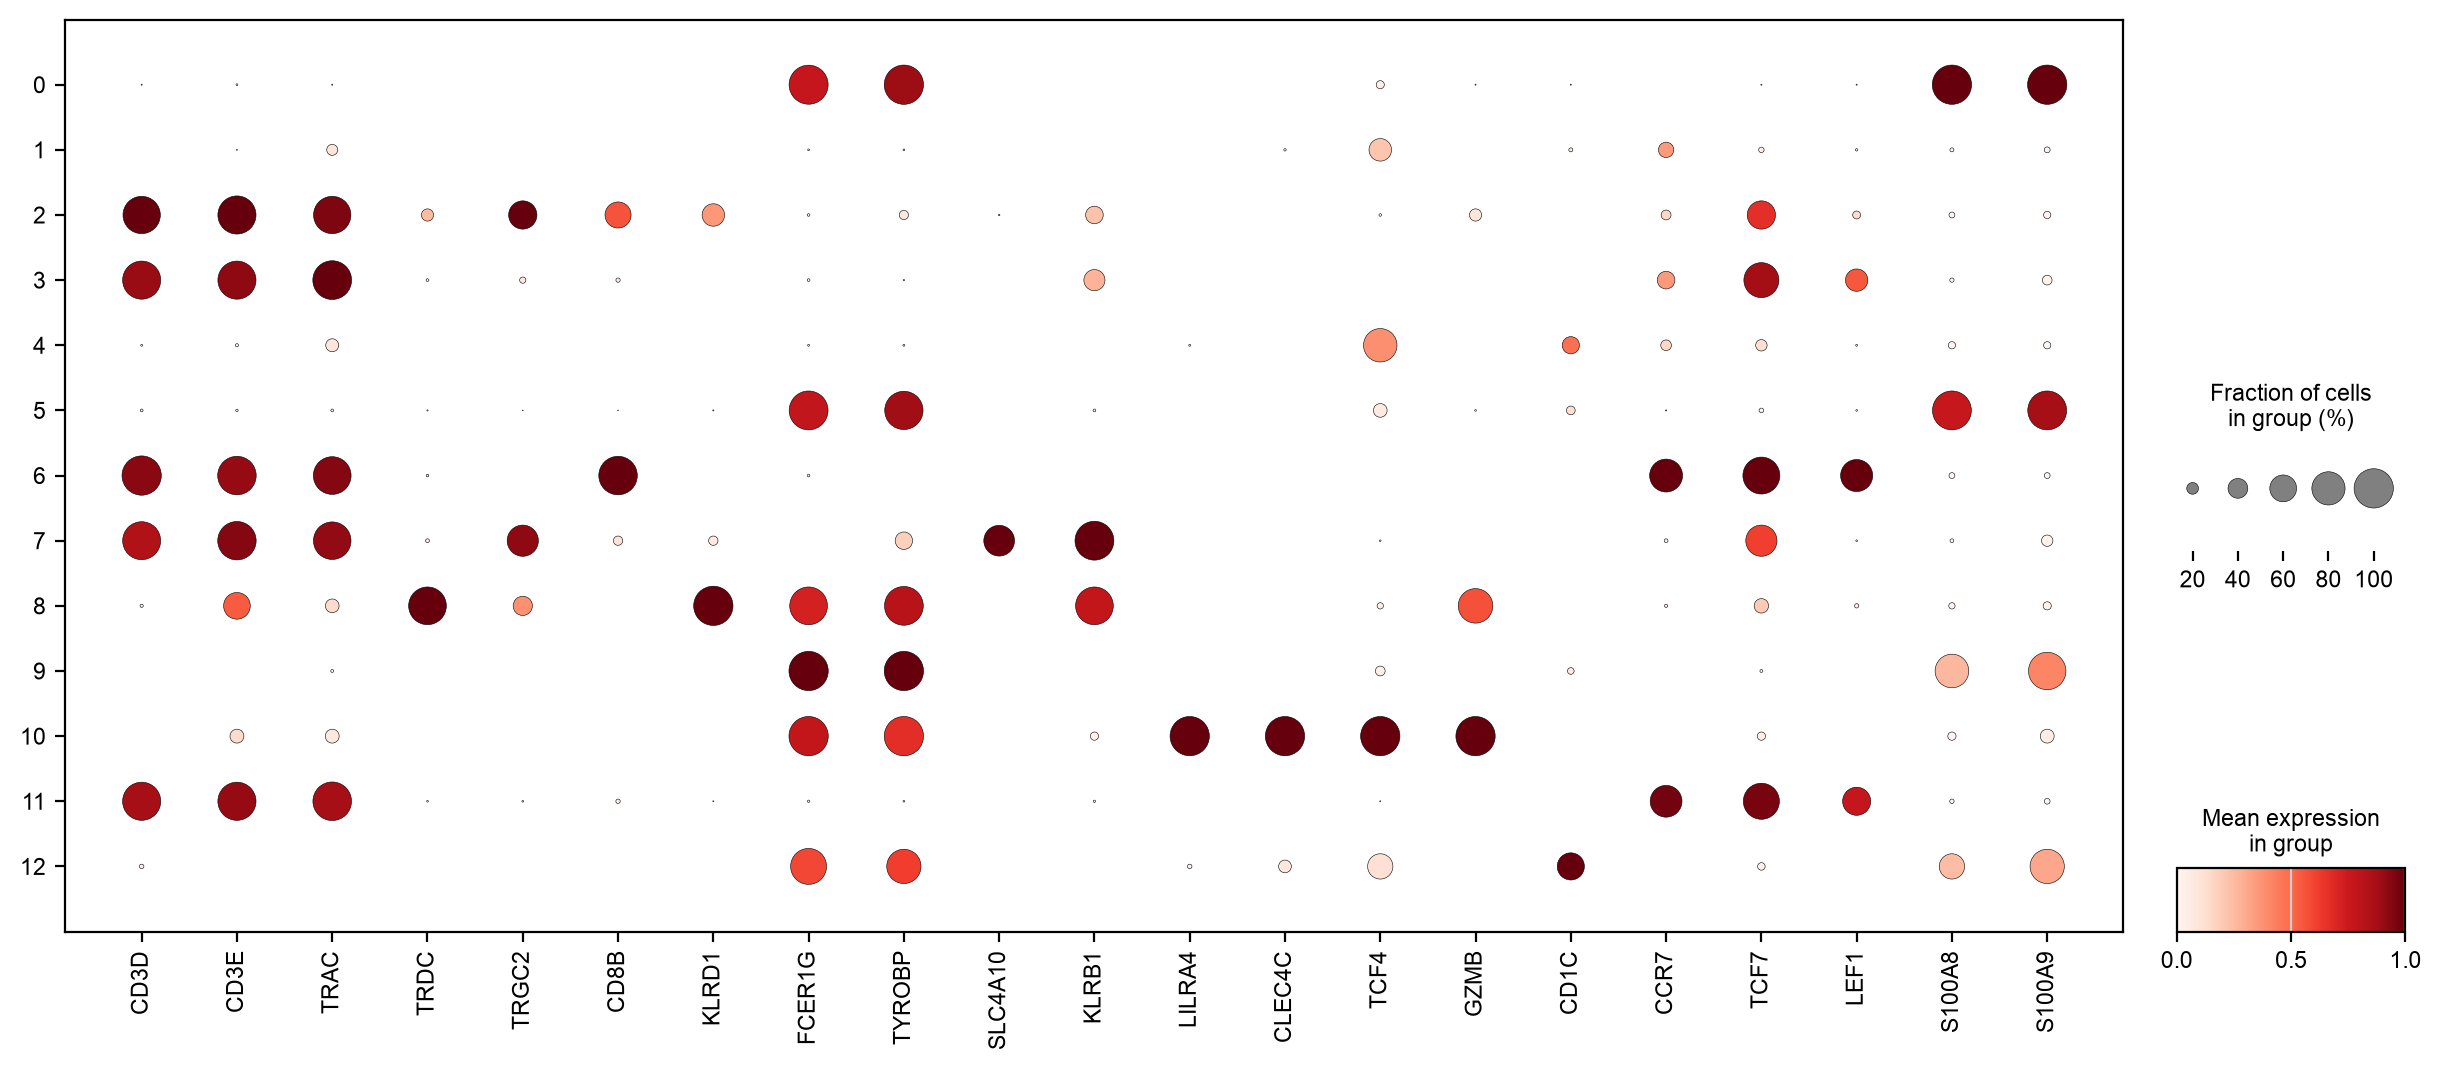

,CD3D,CD3E,TRAC,TRDC,TRGC2,CD8B,KLRD1,FCER1G,TYROBP,SLC4A10,...,LILRA4,CLEC4C,TCF4,GZMB,CD1C,CCR7,TCF7,LEF1,S100A8,S100A9
leiden,,,,,,,,,,,,,,,,,,,,,
0,0.01,0.02,0.01,0.00,0.00,0.00,0.00,0.99,1.00,0.00,...,0.00,0.00,0.12,0.01,0.01,0.00,0.01,0.01,1.00,1.00
1,0.00,0.01,0.18,0.00,0.00,0.00,0.00,0.02,0.02,0.00,...,0.00,0.02,0.48,0.00,0.05,0.29,0.07,0.02,0.05,0.08
2,0.93,0.96,0.93,0.21,0.64,0.58,0.47,0.03,0.14,0.01,...,0.00,0.00,0.03,0.21,0.00,0.16,0.64,0.12,0.08,0.11
3,0.96,0.96,0.98,0.03,0.09,0.05,0.00,0.03,0.01,0.00,...,0.00,0.00,0.00,0.00,0.00,0.34,0.86,0.47,0.05,0.16
4,0.02,0.04,0.23,0.00,0.00,0.00,0.00,0.02,0.02,0.00,...,0.02,0.00,0.81,0.00,0.33,0.18,0.19,0.02,0.11,0.11
5,0.03,0.02,0.03,0.01,0.00,0.00,0.01,0.99,0.97,0.00,...,0.00,0.00,0.25,0.01,0.13,0.01,0.06,0.01,0.99,0.99
6,1.00,0.97,0.95,0.03,0.00,0.97,0.00,0.03,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.79,0.92,0.76,0.08,0.08
7,0.96,0.97,0.94,0.04,0.74,0.15,0.15,0.00,0.34,0.72,...,0.00,0.00,0.01,0.00,0.00,0.04,0.74,0.01,0.04,0.19
8,0.04,0.60,0.25,0.95,0.39,0.00,1.00,0.95,0.98,0.00,...,0.00,0.00,0.09,0.84,0.00,0.04,0.26,0.05,0.09,0.12


In [13]:
review_requested = P['review_markers'].split(',')
review_present = [g for g in review_requested if g in adata.raw.var_names]
print('Missing follow-up markers:', sorted(set(review_requested) - set(review_present)))
sc.pl.dotplot(adata, review_present, groupby='leiden', use_raw=True,
              standard_scale='var', dendrogram=False, figsize=(15, 6), show=False)
plt.savefig(FIG / '12_followup_markers.png', dpi=160, bbox_inches='tight')
plt.show()
review_values = adata.raw[:, review_present].X.toarray()
review_means = pd.DataFrame(review_values, index=adata.obs_names,
    columns=review_present).groupby(adata.obs.leiden, observed=True).mean()
review_fractions = pd.DataFrame(review_values > 0, index=adata.obs_names,
    columns=review_present).groupby(adata.obs.leiden, observed=True).mean()
review_means.to_csv(OUT / 'followup_marker_mean_expression.csv')
review_fractions.to_csv(OUT / 'followup_marker_fraction_expressing.csv')
display(review_fractions.round(2))


### Reviewed interpretation of this seeded run

This table describes the observed run with seed 42, 20 PCs, 15 neighbors, and
Leiden resolution 0.6. It is a **human review of model and marker evidence**, not
an automatic cluster-to-type dictionary. If you change parameters, use the newly
executed summaries above and review these interpretations again.

| Cluster | Cells | Working interpretation | Evidence / caution |
|---|---:|---|---|
| 0 | 115 | Classical CD14+ monocytes, S100A8/A9-high | CD14, LYZ, S100A8, S100A9; 100% classical-monocyte model labels |
| 1 | 126 | Naive B cells | MS4A1, CD79A, TCL1A, IGHD/IGHM |
| 2 | 76 | Cytotoxic T cells; mixed effector/memory-like states | CD3E, CD8A/B, CCL5, NKG7; only 54% share the leading fine label |
| 3 | 174 | IL7R+ helper T cells; mixed naive/memory/effector-like states | CD3E, IL7R, TRAC; 63% leading fine label and 31 heterogeneous cells |
| 4 | 57 | Memory B cells | MS4A1, CD79A, TNFRSF13B, IGHG genes |
| 5 | 208 | Classical CD14+ monocytes, CPVL/LGALS2-high | CD14, LYZ, CPVL; 204 classical monocytes and 4 DC2 labels |
| 6 | 38 | Naive/central-memory-like CD8 T cells | CD3E, CD8A/B, CCR7, TCF7, LEF1 |
| 7 | 68 | MAIT-like T cells | CD3E, IL7R, NKG7, SLC4A10, KLRB1; all 68 raw predictions were MAIT |
| 8 | 57 | NK-like cytotoxic cells; review T-cell-associated RNA | GNLY, NKG7, KLRD1, FCER1G, TYROBP; CD3E/TRDC signal merits follow-up |
| 9 | 32 | Nonclassical FCGR3A+ monocytes | FCGR3A, CST3, LYZ, CDKN1C; weaker CD14 |
| 10 | 8 | Plasmacytoid dendritic cells (pDC), small group | 8 cells; LILRA4, CLEC4C, TCF4, GZMB; all raw predictions pDC |
| 11 | 130 | Naive/central-memory-like helper T cells | CD3E, IL7R, CCR7, TCF7, LEF1 |
| 12 | 18 | Conventional dendritic cells, DC2-like; subtype mixed | 18 cells; FCER1A, CST3, CD1C; raw labels include 11 DC2 and 5 DC1 |

Two monocyte clusters share the same broad lineage; their separation is not proof
of two distinct cell types. Clusters 2 and 3 have mixed fine labels, so we retain
broad T-cell interpretations. The eight-cell pDC group is marker-supported but
small. Cluster 12's majority-voted DC2 label conceals mixed raw dendritic subtypes.
The NK-like group has strong NK markers and little CD3D or CD8B, but CD3E/TRDC
expression prevents treating it as an unquestioned pure lineage. These data alone
do not distinguish all possible ambient-RNA, quantification, or mixed-cell effects.

Majority voting changed 155 labels, including 45 cells assigned **Heterogeneous**.
Both raw model labels and voted labels are saved. A unanimous voted label is not
independent validation, particularly for small or internally mixed groups.


## 10 · Save and reopen the annotated result

The saved object contains normalized expression, raw-count layers, QC metrics,
HVG annotations, PCA, neighbor graph, UMAP, Leiden clusters, and CellTypist labels.
Parameters, package versions, input/reference/model hashes, and the cluster summary
are embedded as provenance. The all-barcode QC table and marker tables are separate
files so later dashboard work can display filtering decisions and markers.

We write through a temporary filename, reopen the file, and validate it before
replacing the final result. That catches incomplete or incompatible exports. The
original Stage 1 count matrix remains the unchanged source for rerunning analysis.

In [14]:
def sha256_file(path):
    with Path(path).open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

adata.uns['analysis_parameters'] = {k: v for k, v in P.items() if k.startswith(
    ('analysis_', 'qc_', 'normalization_', 'hvg_', 'pca_', 'neighbors_', 'leiden_',
     'umap_', 'marker_', 'celltypist_', 'pbmc_', 'review_')) or k == 'seed'}
adata.uns['software_versions'] = versions
adata.uns['qc_thresholds'] = {k: v for k, v in P.items() if k.startswith('qc_')}
adata.uns['cluster_summary'] = cluster_summary.set_index('cluster')
adata.uns['provenance'] = {
    'input_sha256': sha256_file(ROOT / P['analysis_input']),
    'mapping_sha256': sha256_file(ROOT / P['t2g']), 'model_sha256': model_hash,
    'celltypist_model_feature_overlap': len(overlap),
    'celltypist_model_features': len(model.features),
    'input_barcodes': input_shape[0], 'cells_after_qc': adata.n_obs,
    'python': platform.python_version(), 'reference': 'GRCh38 / Ensembl 108 standard',
    'qc_metrics_definition': 'UMI counts before rare-gene filtering; mitochondrial UMI percentage',
    'celltypist_expression': 'all mapped features, log1p normalized to 10000 per cell',
}
output_path = ROOT / P['analysis_output']
output_path.parent.mkdir(parents=True, exist_ok=True)
temporary_output = output_path.with_name(output_path.stem + '.tmp.h5ad')
adata.write_h5ad(temporary_output, compression='gzip')
check = sc.read_h5ad(temporary_output)
assert check.shape == adata.shape and check.obs_names.equals(adata.obs_names)
assert check.var_names.equals(adata.var_names) and check.var_names.is_unique
assert check.obsm['X_umap'].shape == (check.n_obs, 2)
assert np.isfinite(check.obsm['X_umap']).all()
assert check.obs[['leiden', 'cell_type']].notna().all().all()
assert sp.issparse(check.X) and sp.issparse(check.layers['counts'])
assert (check.layers['counts'] != adata.layers['counts']).nnz == 0
assert (check.X != adata.X).nnz == 0
assert np.equal(check.layers['counts'].data, np.floor(check.layers['counts'].data)).all()
assert np.isfinite(check.X.data).all() and (check.X.data >= 0).all()
assert 'rank_genes_groups' in check.uns and 'connectivities' in check.obsp
temporary_output.replace(output_path)
run_record = {'cells': check.n_obs, 'genes': check.n_vars,
              'clusters': int(check.obs.leiden.nunique()),
              'celltypist_labels': int(check.obs.cell_type.nunique()),
              'input_shape': list(input_shape), 'gene_mapping': mapping_summary,
              'parameters': adata.uns['analysis_parameters'],
              'provenance': adata.uns['provenance'], 'versions': versions,
              'output_sha256': sha256_file(output_path), 'reopened_and_validated': True}
(OUT / 'run_record.json').write_text(json.dumps(run_record, indent=2) + '\n')
print('Saved and validated:', output_path.relative_to(ROOT))
print(f'{check.n_obs:,} cells × {check.n_vars:,} genes; '
      f'{check.obs.leiden.nunique()} Leiden clusters; {check.obs.cell_type.nunique()} CellTypist labels.')

... storing 'gene_symbol' as categorical


Saved and validated: results/annotated.h5ad
1,107 cells × 17,581 genes; 13 Leiden clusters; 14 CellTypist labels.


## Sources and interpretation limits

- [Scanpy preprocessing and clustering](https://scanpy.readthedocs.io/en/latest/tutorials/basics/clustering.html)
- [Scanpy PBMC marker examples](https://scanpy.readthedocs.io/en/latest/tutorials/basics/clustering-2017.html)
- [CellTypist input scale and majority voting](https://www.celltypist.org/tutorials/onlineguide)
- [CellTypist annotation API](https://celltypist.readthedocs.io/en/latest/celltypist.annotate.html)
- [Official model catalog](https://celltypist.cog.sanger.ac.uk/models/models.json)
- [10x dataset and attribution](https://www.10xgenomics.com/datasets/1-k-pbm-cs-from-a-healthy-donor-v-3-chemistry-3-standard-3-0-0)

This single-donor exploration supports cell-type hypotheses, not population-level
inference. Thresholds, reference gene coverage, ambient RNA, unresolved doublets,
and model-domain differences can affect labels. UMAP is exploratory; marker
patterns and model agreement are supporting evidence rather than independent truth.
**Stop at Stage 2 for review.** Nextflow modules and containers are Stage 3.